# Time to first IT job: research walkthrough

**A Survival-Analysis Framework for Predicting and Explaining Time-to-Employment for Final-Year Information Technology Undergraduates and Graduates in Sri Lanka** - M. S. F. Shazna

This notebook walks through the whole analysis behind the dissertation, from the cleaned survey data to the final
results, with every table and chart produced in place.

**How it works**

* Every step calls the project's own code in `core/`, so the numbers here are produced by the same functions as the
  thesis and the app (no logic is copied into the notebook).
* **Training and tuning run live** on the training set (620 graduates) and are scored on the validation set (133).
* **The locked test set (132) is not evaluated here.** It was used once, in `core/evaluate.py`, after the model was
  chosen; its results are loaded from `artifacts/`. This keeps the rule "test set used once" intact.
* Only counts, summaries and charts are shown - never individual respondents.
* Reports that are regenerated here are written to a temporary folder, so `artifacts/` is not changed.
* **No private data?** Set `USE_SYNTHETIC = True` in the first code cell. The notebook then copies the code to a
  temporary folder, generates synthetic survey data with the project's own generator and runs the full pipeline there
  (about 3 extra minutes). The real data and results are never touched. The "What this shows" notes describe the
  **real** results; with synthetic data the numbers will differ, and the SUS, LLM-benchmark and coding-agreement
  sections, which need real human responses, are skipped. The diagnostics in section 9 always use the log-normal AFT
  model, the one selected on the real data.

| Section | Content |
|---|---|
| [1](#s1) | Setup and data overview |
| [2](#s2) | Cleaning and outcome construction |
| [3](#s3) | Exploratory analysis: correlations, skill ratings, reliability, factor structure |
| [4](#s4) | Time to first IT job: Kaplan-Meier, groups, competing paths |
| [5](#s5) | The fixed train / validation / test split |
| [6](#s6) | Training and hyperparameter tuning |
| [7](#s7) | Model comparison and the pre-set selection rule |
| [8](#s8) | Model checks: AFT fit, proportional hazards, time ratios |
| [9](#s9) | Diagnostics: learning curve, baselines, time-dependent AUC, Brier score, error analysis |
| [10](#s10) | Final result on the locked test set (loaded) and fairness |
| [11](#s11) | Robustness |
| [12](#s12) | Skill gaps: graduates, employers and job advertisements (RQ2) |
| [13](#s13) | Usability and the LLM benchmark (RQ4) |
| [14](#s14) | Secondary analyses: feature sets, other models, clustering, simulation, job market, questionnaire, tests |
| [15](#s15) | Summary and consistency check against the reported results |

<a id="s1"></a>

## 1. Setup and data overview

The first cell finds the project folder, imports the project's modules and defines three small display helpers.

In [1]:
# ---- Choose the data ----------------------------------------------------------------------------------------------
USE_SYNTHETIC = False   # True: run everything on generated data in a temporary copy (no private data needed)

# ---- Locate the project and make its code importable ------------------------------------------------------------
import io, json, os, shutil, subprocess, sys, tempfile, warnings
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # works from notebooks/ or the root

if USE_SYNTHETIC:
    # Copy the code into a temporary folder and run the whole pipeline there on synthetic data, so the real
    # data/ and artifacts/ folders are never read or overwritten.
    ROOT = Path(tempfile.mkdtemp(prefix="walkthrough_synthetic_"))
    for folder in ("core", "benchmark", "api"):
        shutil.copytree(PROJECT / folder, ROOT / folder, ignore=shutil.ignore_patterns("__pycache__"))
    shutil.copytree(PROJECT / "docs" / "questionnaires", ROOT / "docs" / "questionnaires")
    for folder in ("data/raw", "data/processed", "data/reference", "artifacts/figures"):
        (ROOT / folder).mkdir(parents=True, exist_ok=True)
    for name in ("job_ad_coding_rules.json", "job_ad_technology_rules.json", "learning_resources.csv",
                 "university_types_SYNTHETIC.csv"):           # the fictional institutions' lookup, not the real one
        shutil.copy(PROJECT / "data" / "reference" / name, ROOT / "data" / "reference" / name)
    print("Generating synthetic data and running the full pipeline (about 3 minutes)...")
    run = subprocess.run([sys.executable, "-m", "core.run_all", "--synthetic", "--quick"], cwd=ROOT,
                         capture_output=True, text=True)
    if run.returncode:
        raise RuntimeError(run.stdout[-3000:] + run.stderr[-3000:])
    print("SYNTHETIC MODE: every number below comes from generated data, not the survey.")
else:
    ROOT = PROJECT

os.chdir(ROOT)                      # the project's code reads data/ and artifacts/ relative to the root
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")   # keep the outputs readable (convergence notes from the survival libraries)

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")               # the project's plotting code writes PNG files; we display them below
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# The project's own modules - the notebook only calls them, it re-implements nothing
from core import (baselines, construct_validity, deepsurv_curves, sus_study, eda_figures, error_analysis, evaluate, evaluation_figures,
                  learning_curve, preprocess, sample_comparison, schema, splits, thesis_results,
                  time_dependent_metrics, tuning_results)

ART = ROOT / "artifacts"            # saved results of the main pipeline (python -m core.run_all)
FIG = ART / "figures"

# Scratch folder: reports regenerated in this notebook go here, so artifacts/ is never overwritten
TMP = Path(tempfile.mkdtemp(prefix="walkthrough_"))
(TMP / "figures").mkdir()
shutil.copy(ART / "model_comparison.csv", TMP / "model_comparison.csv")   # some reports read the tuned settings

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)


def show_png(path, width=900):
    """Display a PNG file (charts written by the project's plotting code)."""
    display(Image(filename=str(path), width=width))


def show_fig(fig, width=900):
    """Display a matplotlib figure made in this notebook."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=130, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.close(fig)
    display(Image(data=buf.getvalue(), width=width))


# Readable names for the columns and codes the project's functions return
COLUMN_NAMES = {
    "uno_c": "Uno's C", "uno_c_mean": "Uno's C", "uno_c_lo": "95% CI low", "uno_c_hi": "95% CI high",
    "uno_c_sd": "SD", "uno_c_min": "Lowest", "uno_c_max": "Highest", "harrell_c_mean": "Harrell's C",
    "ibs": "IBS", "ibs_mean": "IBS", "cal_err_3m_mean": "Calibration error 3 m", "cal_err_6m_mean": "Calibration error 6 m",
    "cal_err_12m_mean": "Calibration error 12 m", "candidate": "Candidate", "label": "Model", "params": "Setting",
    "aic": "AIC", "chosen": "Chosen", "matches_main_analysis": "Matches main analysis", "model": "Model",
    "kmo": "KMO", "bartlett_chi2": "Bartlett chi-square", "bartlett_df": "Bartlett df",
    "factors_parallel_analysis": "Factors (parallel analysis)", "alpha": "Cronbach's alpha", "alpha_lo": "alpha CI low",
    "alpha_hi": "alpha CI high", "omega": "McDonald's omega", "ave": "AVE", "loading_min": "Lowest loading",
    "loading_max": "Highest loading", "block": "Block", "item": "Item", "loading": "Loading",
    "communality": "Communality", "predictor": "Predictor", "hr": "HR per SD", "lo": "95% CI low", "hi": "95% CI high",
    "vif": "VIF", "auc_3m": "AUC 3 m", "auc_6m": "AUC 6 m", "auc_12m": "AUC 12 m", "auc_mean": "Mean AUC",
    "diff_vs_selected": "Difference from selected", "diff_lo": "Difference CI low", "diff_hi": "Difference CI high",
    "selected_better_share": "Selected better in", "fraction": "Share of training set", "n_train": "Training graduates",
    "subsamples": "Random subsets", "band": "Actual time to first IT job", "actual_mean": "Mean actual (months)",
    "predicted_mean": "Mean predicted median", "mean_error": "Mean error", "mae": "Mean absolute error",
    "input": "Input", "worst": "Worst-predicted tenth", "rest": "Rest", "skill": "Skill", "kind": "Type",
    "graduate_mean": "Graduates (mean)", "employer_mean": "Employers (mean)", "gap": "Gap", "rank_biserial": "Rank-biserial",
    "q": "q (BH)", "ad_share": "Share of ads", "predicted_6m": "Predicted employed by 6 m",
    "observed_6m": "Observed employed by 6 m", "events": "Events", "group": "Group", "level": "Level",
    "mean_answer": "Mean answer", "sd": "SD", "mean_contribution": "Mean contribution", "text": "Statement",
    "tone": "Tone", "measure": "Measure", "sample": "Sample", "published": "Published", "difference": "Difference",
    "source": "Source", "graduates": "Graduates", "split": "Split", "min": "Lowest", "max": "Highest",
    "count": "Settings", "range": "Range", "n_validation": "Validation graduates", "events_validation": "Events",
}
VALUE_NAMES = {**evaluate.LABELS, **evaluation_figures.LABELS, **evaluation_figures.GROUP_LABELS,
               "aft_best": "AFT (best by AIC)", "technical": "Technical", "soft": "Soft", "train": "Train",
               "validation": "Validation", "test": "Test"}


def show_table(obj, digits=None):
    """Display a table with readable column names and labels; anything else is displayed as it is."""
    if isinstance(obj, pd.Series):
        obj = obj.to_frame()
    if not isinstance(obj, pd.DataFrame):
        display(obj)
        return
    t = obj.copy()
    t.columns = [COLUMN_NAMES.get(c, str(c).replace("_", " ").capitalize()) if isinstance(c, str) else c
                 for c in t.columns]
    t.index = [VALUE_NAMES.get(i, i) if isinstance(i, str) else i for i in t.index]
    for c in t.columns[t.dtypes == object]:
        t[c] = t[c].map(lambda v: VALUE_NAMES.get(v, v) if isinstance(v, str) else v)
    display(t.round(digits) if digits is not None else t)


def show_report(name, start=None, stop=None, max_lines=45):
    """Display part of a saved report in artifacts/ (rendered Markdown), from heading `start` up to heading `stop`."""
    if not (ART / name).exists():
        print(f"{name} is not available here (it needs real survey responses or a separate run).")
        return
    lines = (ART / name).read_text(encoding="utf-8").splitlines()
    if start:
        lines = lines[next(i for i, l in enumerate(lines) if l.startswith(start)):]
    if stop:
        end = next((i for i, l in enumerate(lines[1:], 1) if l.startswith(stop)), len(lines))
        lines = lines[:end]
    lines = [l for l in lines if not l.startswith("![") and not l.startswith("_Generated")]   # no file links
    display(Markdown("\n".join(lines[:max_lines])))


print("Project folder:", ROOT)

Project folder: D:\EmployabilityPredictor


**Data overview.** The cleaning step (`python -m core.clean`) records the size of every dataset. All inputs are real:
the main-study graduate and employer surveys and 324 entry-level IT job advertisements.

In [2]:
# ---- Size of every dataset, as recorded by the cleaning step ----------------------------------------------------
info = json.loads((ROOT / "data" / "processed" / "dataset_info.json").read_text(encoding="utf-8"))
print("Synthetic data used:", info["is_synthetic"])          # False: every reported result uses the real data

overview = pd.DataFrame([
    ("Graduate survey responses (raw)", info["raw_n"]),
    ("Final-year students set aside (no outcome yet)", info["final_year_n"]),
    ("Modelling graduates", info["modelling_n"]),
    ("  ... who had found an IT job (events)", info["modelling_events"]),
    ("  ... still searching at the survey (censored)", info["modelling_n"] - info["modelling_events"]),
    ("Employer responses (after cleaning)", info["employers_n"]),
    ("Job advertisements", info["job_ads_n"]),
], columns=["Dataset", "Count"])
show_table(overview)
print(f"Share still searching (censored): {1 - info['modelling_events'] / info['modelling_n']:.1%}")

Synthetic data used: False


,Dataset,Count
0,Graduate survey responses (raw),1175
1,Final-year students set aside (no outcome yet),230
2,Modelling graduates,885
3,... who had found an IT job (events),667
4,... still searching at the survey (censored),218
5,Employer responses (after cleaning),239
6,Job advertisements,324


Share still searching (censored): 24.6%


<a id="s2"></a>

## 2. Cleaning and outcome construction

Each excluded response is recorded with its reason (`data/processed/excluded.csv`). Below, the reasons are counted -
no respondent identifiers are shown.

**Outcome.** The time origin is the month of degree completion. A graduate in a paid IT role is an *event*, with
duration = months from completion to that role; a graduate still searching is *censored* at the survey month.
Survival analysis uses both: the censored graduates tell us they had not found work *by* a given month.

In [3]:
# ---- Why responses were excluded (counts only) ------------------------------------------------------------------
excluded = pd.read_csv(ROOT / "data" / "processed" / "excluded.csv")
reasons = (excluded.groupby(["step", "reason"]).size().rename("Responses").reset_index()
           .sort_values("Responses", ascending=False))
show_table(reasons)
print("Responses excluded or set aside in total:", len(excluded))

,Step,Reason,Responses
4,Not in IT job market,no IT role and Q16 = further studies / not seeking,27
1,Failed attention check,answered the attention-check row (Q18) with something other than 4,24
0,Duplicate submission,identical answers to an earlier submission,4
3,Missing job status,Q17 missing - event unknown,2
5,Outside eligibility window,completed more than 36 months before the survey,2
2,Implausible job start,first job more than 24 months before completion (likely typo),1


Responses excluded or set aside in total: 60


> **What this shows:** Most exclusions are by design: 230 final-year students have no outcome yet and are set aside, and 24 responses failed the attention check. Only a handful were removed for impossible dates.

In [4]:
# ---- The modelling graduates: missing inputs and outcome summary ------------------------------------------------
grads = pd.read_csv(splits.TRAIN_PATH)        # all 885 modelling graduates (train + validation + test)

inputs = ["gpa", "degree_type", "university_type", "internship_months", "certifications_count", "project_count",
          "has_portfolio", "prep_start", "self_learning_freq", "hackathon_count", "open_source", "sdlc_familiarity"]
missing = grads[inputs].isna().sum().rename("Missing").to_frame()
missing["Share"] = (missing["Missing"] / len(grads)).map("{:.1%}".format)
show_table(missing[missing["Missing"] > 0])      # only hackathons has gaps; they are imputed inside the pipeline

print("Graduates hired at or before completion (duration set to 0.5 months):",
      int((grads["duration_months"] <= schema.JOB_BEFORE_GRADUATION_MONTHS).sum()))
show_table(grads.groupby("event")["duration_months"].describe().rename(index={0: "still searching", 1: "found IT job"}))

,Missing,Share
Hackathons,107,12.1%


Graduates hired at or before completion (duration set to 0.5 months): 117


,Settings,Mean,Std,Lowest,25%,50%,75%,Highest
still searching,218.0,8.821101,8.207567,1.0,2.0,6.0,13.0,32.0
found IT job,667.0,4.207646,4.084779,0.5,1.5,3.0,5.0,33.0


### 2.1 Class balance and the distribution of the outcome

In survival analysis the two "classes" are **found an IT job (event)** and **still searching (censored)**. About one
in four graduates was still searching, a moderate level of censoring that survival models handle directly. The
histogram shows how long each group had been followed: months to the first job for those who found one, months of
searching so far for those still looking.

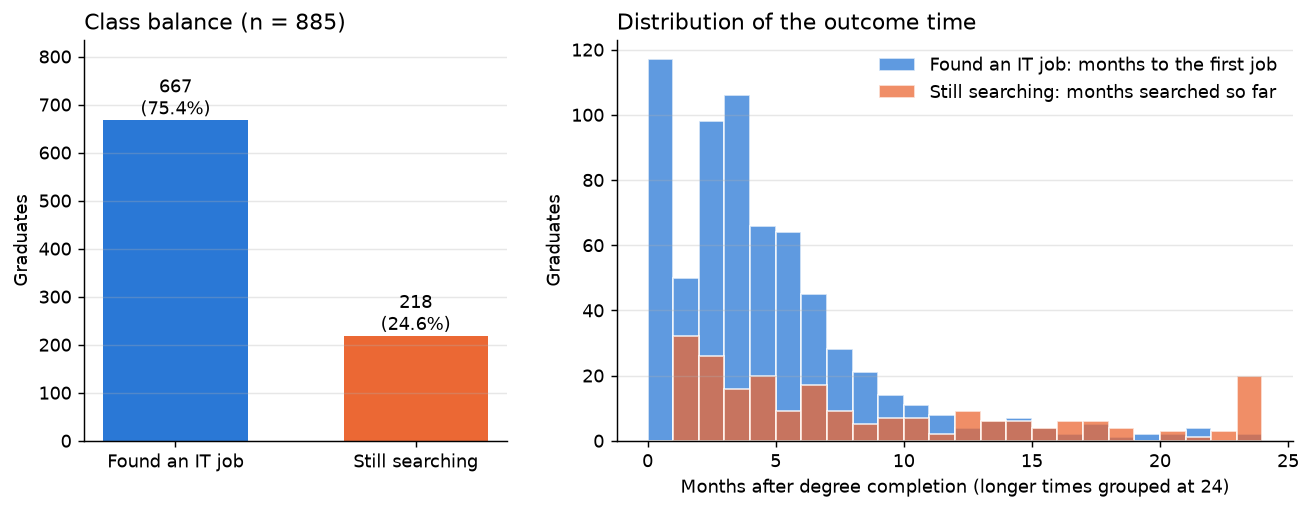

In [5]:
# ---- Class balance: found an IT job vs still searching (all 885 modelling graduates) ----------------------------
FOUND, SEARCHING = "#2a78d6", "#eb6834"          # one colour per outcome, used in every chart below
counts = grads["event"].map({1: "Found an IT job", 0: "Still searching"}).value_counts()
counts = counts.reindex(["Found an IT job", "Still searching"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})
bars = ax1.bar(counts.index, counts.values, color=[FOUND, SEARCHING], width=0.6)
for bar, n in zip(bars, counts.values):           # label each bar with its count and share
    ax1.annotate(f"{n}\n({n / counts.sum():.1%})", (bar.get_x() + bar.get_width() / 2, n),
                 ha="center", va="bottom", fontsize=10)
ax1.set_ylim(0, counts.max() * 1.25)
ax1.set_ylabel("Graduates")
ax1.set_title(f"Class balance (n = {counts.sum()})", loc="left")

# ---- Distribution of the outcome time, by group (0-24 months; a few longer follow-ups are clipped at 24) --------
bins = np.arange(0, 25, 1)
for value, label, colour in ((1, "Found an IT job: months to the first job", FOUND),
                             (0, "Still searching: months searched so far", SEARCHING)):
    times = grads.loc[grads["event"] == value, "duration_months"].clip(upper=24)
    ax2.hist(times, bins=bins, color=colour, alpha=0.75, label=label, edgecolor="white")
ax2.set_xlabel("Months after degree completion (longer times grouped at 24)")
ax2.set_ylabel("Graduates")
ax2.set_title("Distribution of the outcome time", loc="left")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
show_fig(fig)

> **What this shows:** Three in four graduates had found an IT job and one in four was still searching - moderate censoring that survival analysis uses rather than discards. Most first jobs came within six months; the still-searching group is spread out, and the bar at 24 groups the longest searches.

<a id="s3"></a>

## 3. Exploratory analysis

All relationships below are calculated on the **training set only** (620 graduates), so the validation and test sets
stay untouched.

In [6]:
# ---- Load the training set and summarise the predictors in their original units --------------------------------
train = splits.load("train")
valid = splits.load("validation")

raw = preprocess.raw_feature_frame(train)          # predictors before imputation and scaling
show_table(raw.select_dtypes("number").describe().T.round(2))

,Settings,Mean,Std,Lowest,25%,50%,75%,Highest
GPA,620.0,3.09,0.37,2.10,2.80,3.10,3.30,4.00
Internship months,620.0,5.23,3.54,0.00,3.00,6.00,6.00,18.00
Certifications,620.0,1.02,1.14,0.00,0.00,1.00,2.00,5.00
Projects,620.0,2.67,1.89,0.00,1.00,3.00,4.00,8.00
Technical skill score,620.0,2.98,0.57,1.24,2.57,2.94,3.35,4.65
Soft-skill score,620.0,3.64,0.66,1.33,3.11,3.67,4.11,5.00
Portfolio,620.0,0.43,0.49,0.00,0.00,0.00,1.00,1.00
Years of preparation,620.0,1.52,0.96,0.00,1.00,2.00,2.00,4.00
Self-learning frequency,620.0,3.25,1.00,1.00,3.00,3.00,4.00,5.00
Hackathons,548.0,1.11,1.16,0.00,0.00,1.00,2.00,6.00


### 3.0 Distribution of each predictor

Histograms of the numeric predictors and bar charts of the categorical ones (training set). Skewed counts (most
graduates with few certifications or hackathons) and heaping (many internships of exactly 6 months) are visible here.

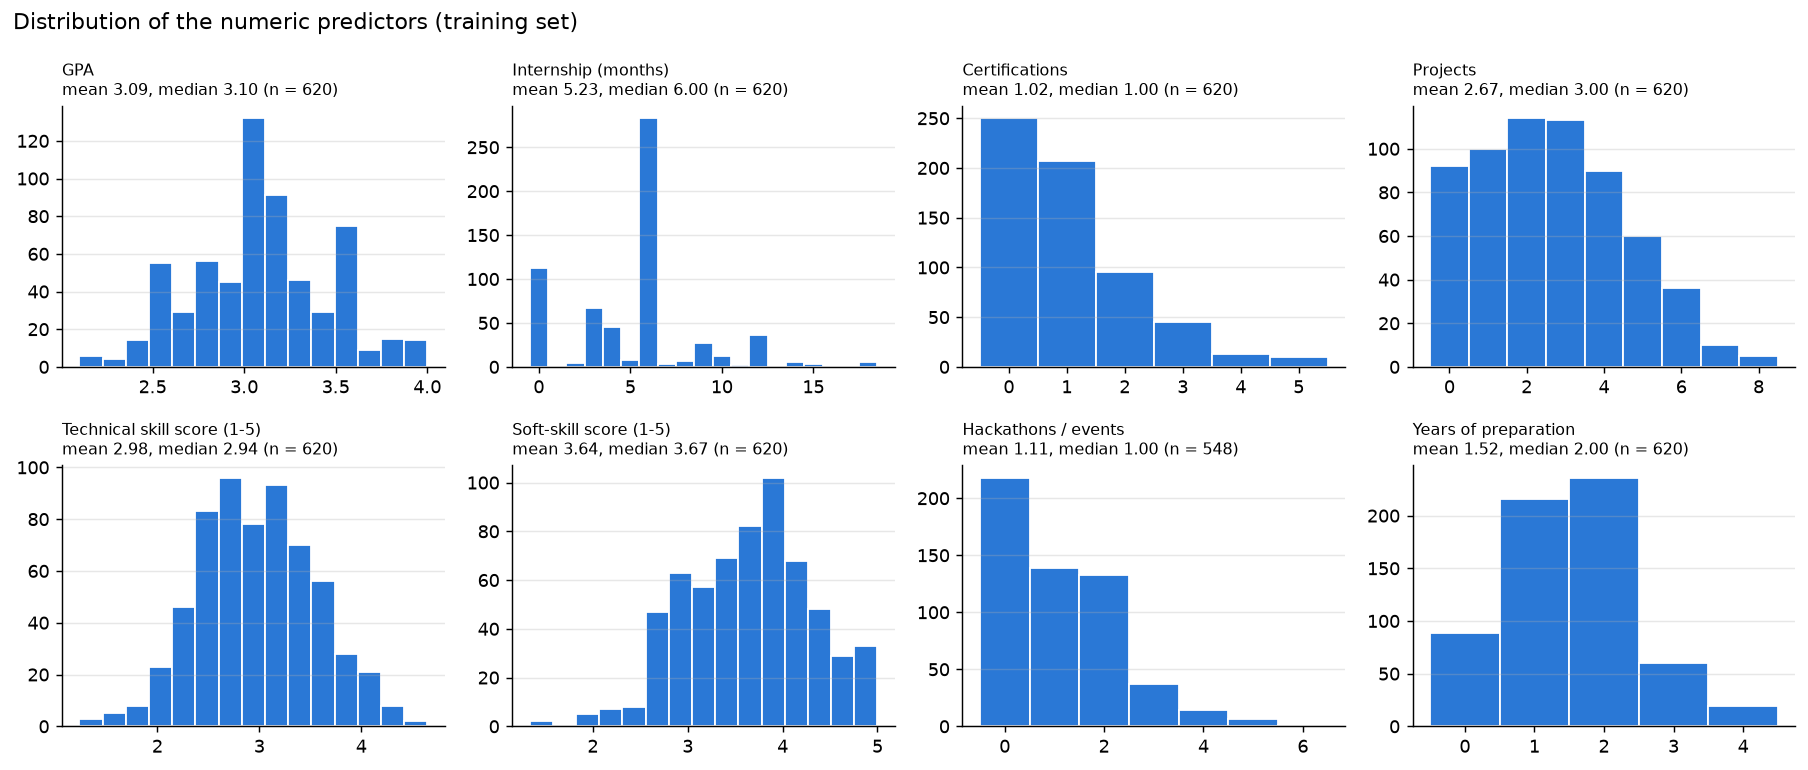

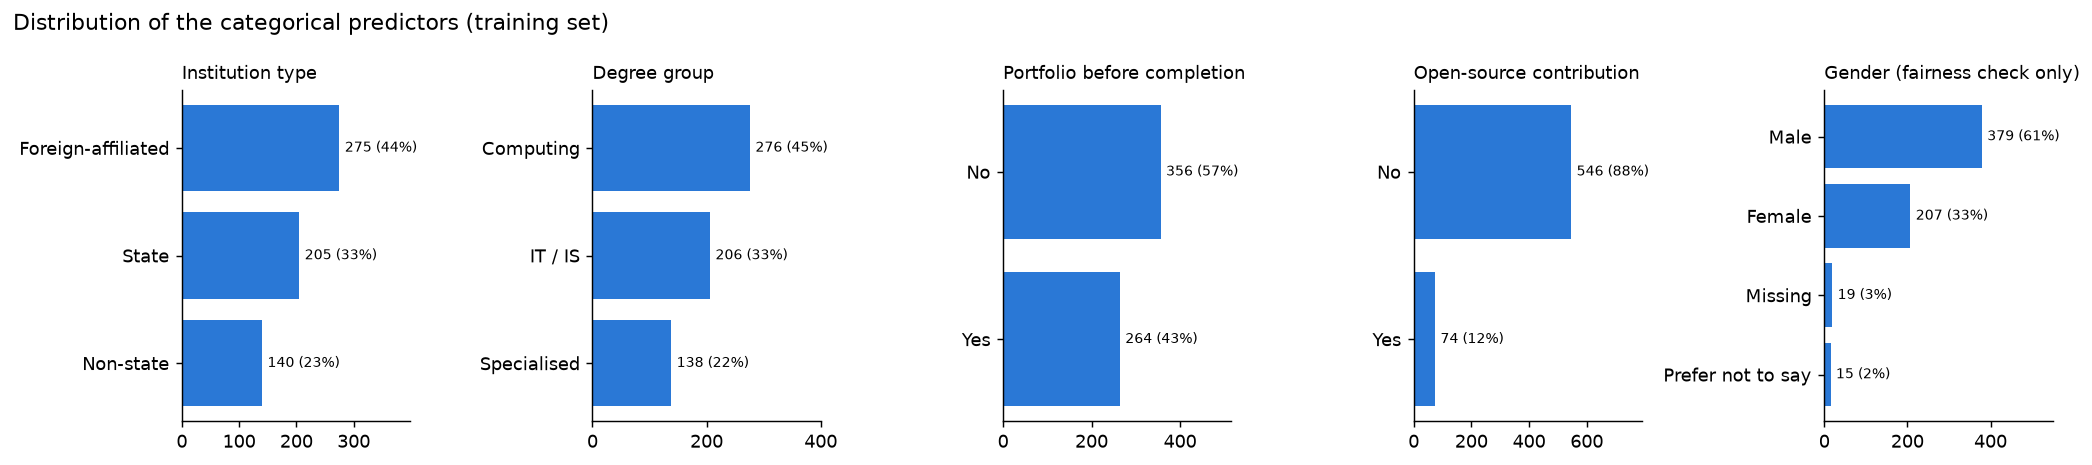

In [7]:
# ---- Histograms of the numeric predictors (training set, original units) ----------------------------------------
numeric = {"gpa": "GPA", "internship_months": "Internship (months)", "certifications_count": "Certifications",
           "project_count": "Projects", "technical_mean": "Technical skill score (1-5)",
           "soft_mean": "Soft-skill score (1-5)", "hackathon_count": "Hackathons / events", "prep_years": "Years of preparation"}
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (col, label) in zip(axes.ravel(), numeric.items()):
    values = pd.to_numeric(raw[col], errors="coerce").dropna()
    discrete = bool(np.allclose(values, values.round()))   # whole-number counts: one bar per value; others: 15 bins
    ax.hist(values, bins=np.arange(values.min(), values.max() + 2) - 0.5 if discrete else 15,
            color="#2a78d6", edgecolor="white")
    ax.set_title(f"{label}\nmean {values.mean():.2f}, median {values.median():.2f} (n = {len(values)})",
                 fontsize=9, loc="left")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Distribution of the numeric predictors (training set)", x=0.01, ha="left")
fig.tight_layout()
show_fig(fig)

# ---- Bar charts of the categorical predictors, plus gender (used only in the fairness check, never as an input) ---
categorical = {"university_type": "Institution type", "degree_group": "Degree group",
               "has_portfolio": "Portfolio before completion", "open_source": "Open-source contribution",
               "gender": "Gender (fairness check only)"}
READABLE = {"foreign_affiliated": "Foreign-affiliated", "non_state": "Non-state", "state": "State",
            "computing": "Computing", "it_is": "IT / IS", "specialised": "Specialised", "yes": "Yes", "no": "No",
            "male": "Male", "female": "Female", "prefer_not_to_say": "Prefer not to say", "missing": "Missing"}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, (col, label) in zip(axes, categorical.items()):
    shares = train[col].fillna("missing").astype(str).replace(READABLE).value_counts()
    ax.barh(shares.index[::-1], shares.values[::-1], color="#2a78d6")
    for i, n in enumerate(shares.values[::-1]):    # write the count and share at the end of each bar
        ax.annotate(f"{n} ({n / shares.sum():.0%})", (n, i), xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=8)
    ax.set_xlim(0, shares.max() * 1.45)
    ax.set_title(label, fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Distribution of the categorical predictors (training set)", x=0.01, ha="left")
fig.tight_layout()
show_fig(fig)

> **What this shows:** GPA clusters around 3.0-3.5; internship months are heaped at 6 (the usual internship length); certifications, projects and hackathons are skewed towards few. The two skill scores are roughly symmetric. Institution types and degree groups are all well represented; few graduates contributed to open source (12%).

### 3.1 Correlation between predictors

Spearman correlations (pairwise complete). Strong correlations between predictors would make individual effects hard
to separate (multicollinearity).

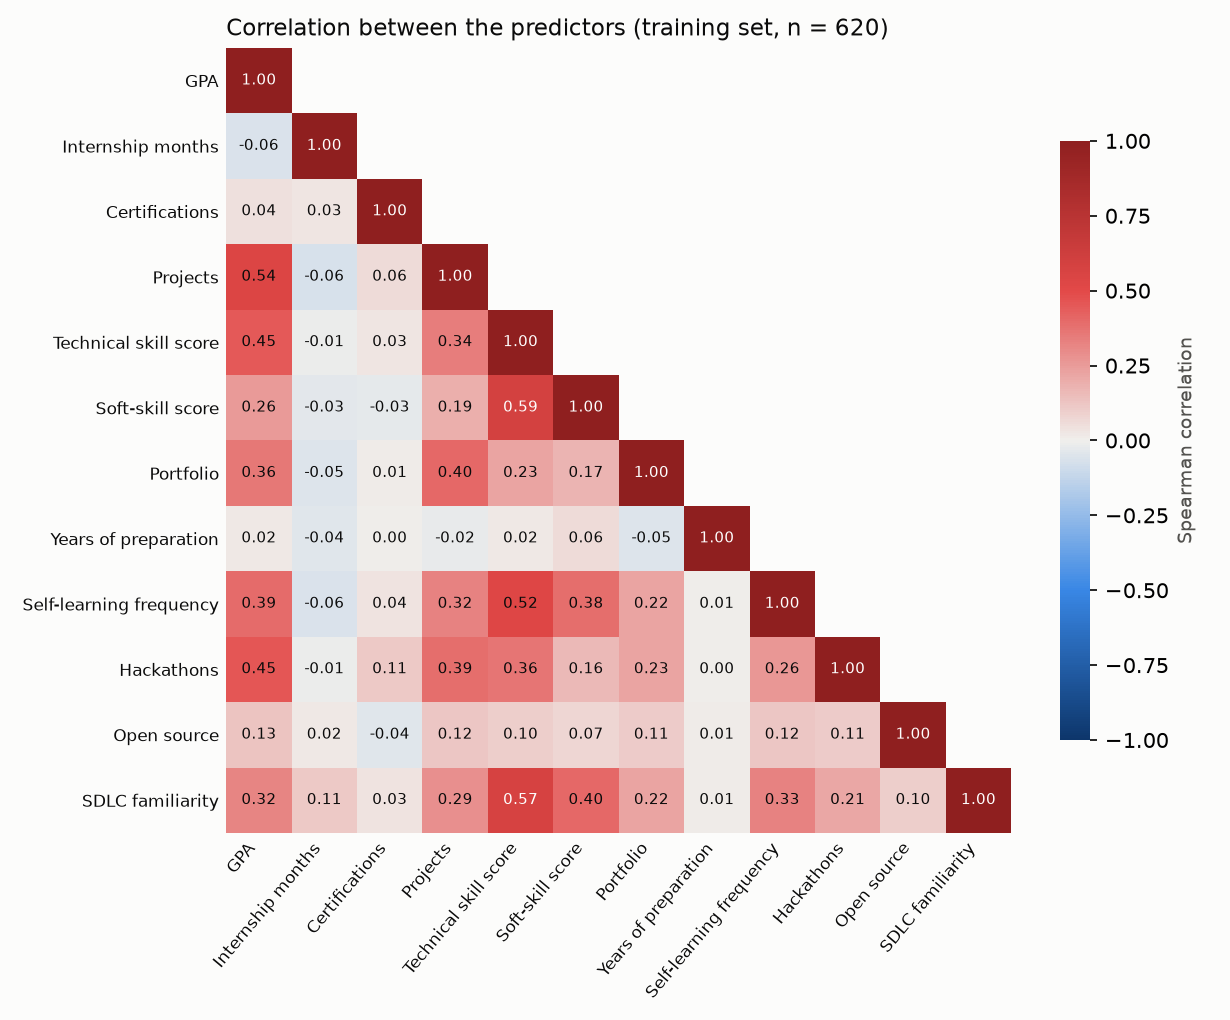

Strongest correlation: Technical skill score and Soft-skill score, rho = 0.59 - moderate, so no predictor duplicates another


In [8]:
# ---- Correlation heatmap (core/eda_figures.py) --------------------------------------------------------------------
corr = eda_figures.spearman(train)
eda_figures.plot_correlation(corr, len(train), TMP / "figures" / "correlation.png")
show_png(TMP / "figures" / "correlation.png", width=760)

# The strongest correlation between two different predictors
off_diagonal = corr.where(~np.eye(len(corr), dtype=bool)).abs().stack()
a, b = off_diagonal.idxmax()
print(f"Strongest correlation: {a} and {b}, rho = {corr.loc[a, b]:.2f} - moderate, so no predictor duplicates another")

> **What this shows:** No two predictors move together strongly: the highest correlation is 0.59 (technical and soft skill scores), so each predictor carries some information of its own.

### 3.1.1 Each predictor on its own, and variance inflation factors (thesis Table E.2)

A univariate Cox model per predictor (hazard ratio per SD: above 1 = finding work sooner) and the variance inflation
factor (VIF) of each predictor given the others. VIFs below 5 (here all below 2.6) mean multicollinearity is not a
concern.

In [9]:
# ---- Univariate Cox per SD and VIF, training set (core/construct_validity.py) ------------------------------------
train_scored = construct_validity.with_scores(train)             # adds the block scores and numeric codes
e2 = construct_validity.univariate_and_vif(train_scored)
show_table(e2.assign(**{"HR per SD (95% CI)": e2.apply(lambda r: f"{r.hr:.2f} ({r.lo:.2f}-{r.hi:.2f})", axis=1)})
        [["predictor", "n", "HR per SD (95% CI)", "p", "vif"]].round(4))

,Predictor,N,Hr per sd (95% ci),P,VIF
0,GPA,620,1.33 (1.21-1.45),0.0000,1.8935
1,Projects,620,1.24 (1.13-1.36),0.0000,1.7093
2,Technical skill score,620,1.22 (1.12-1.34),0.0000,2.5280
3,Hackathons,548,1.15 (1.06-1.26),0.0016,1.3790
4,Self-learning frequency,620,1.15 (1.05-1.26),0.0026,1.5852
5,Portfolio,620,1.14 (1.04-1.24),0.0061,1.2851
6,SDLC familiarity,620,1.13 (1.04-1.24),0.0066,1.6216
7,Certifications,620,1.12 (1.03-1.23),0.0093,1.0252
8,Soft-skill score,620,1.11 (1.01-1.22),0.0338,1.6066
9,Internship months,620,1.10 (1.01-1.20),0.0334,1.0541


> **What this shows:** On its own, almost every predictor is linked to finding work sooner (GPA most, HR 1.33). Once they are considered together (section 8.3) only GPA and internship remain clear, because many predictors overlap with GPA. Every VIF is below 2.6, so the overlap is not strong enough to distort the adjusted estimates.

### 3.2 Skill self-ratings

How graduates rated the 17 technical and 9 soft skills at degree completion (1-5), sorted by mean.

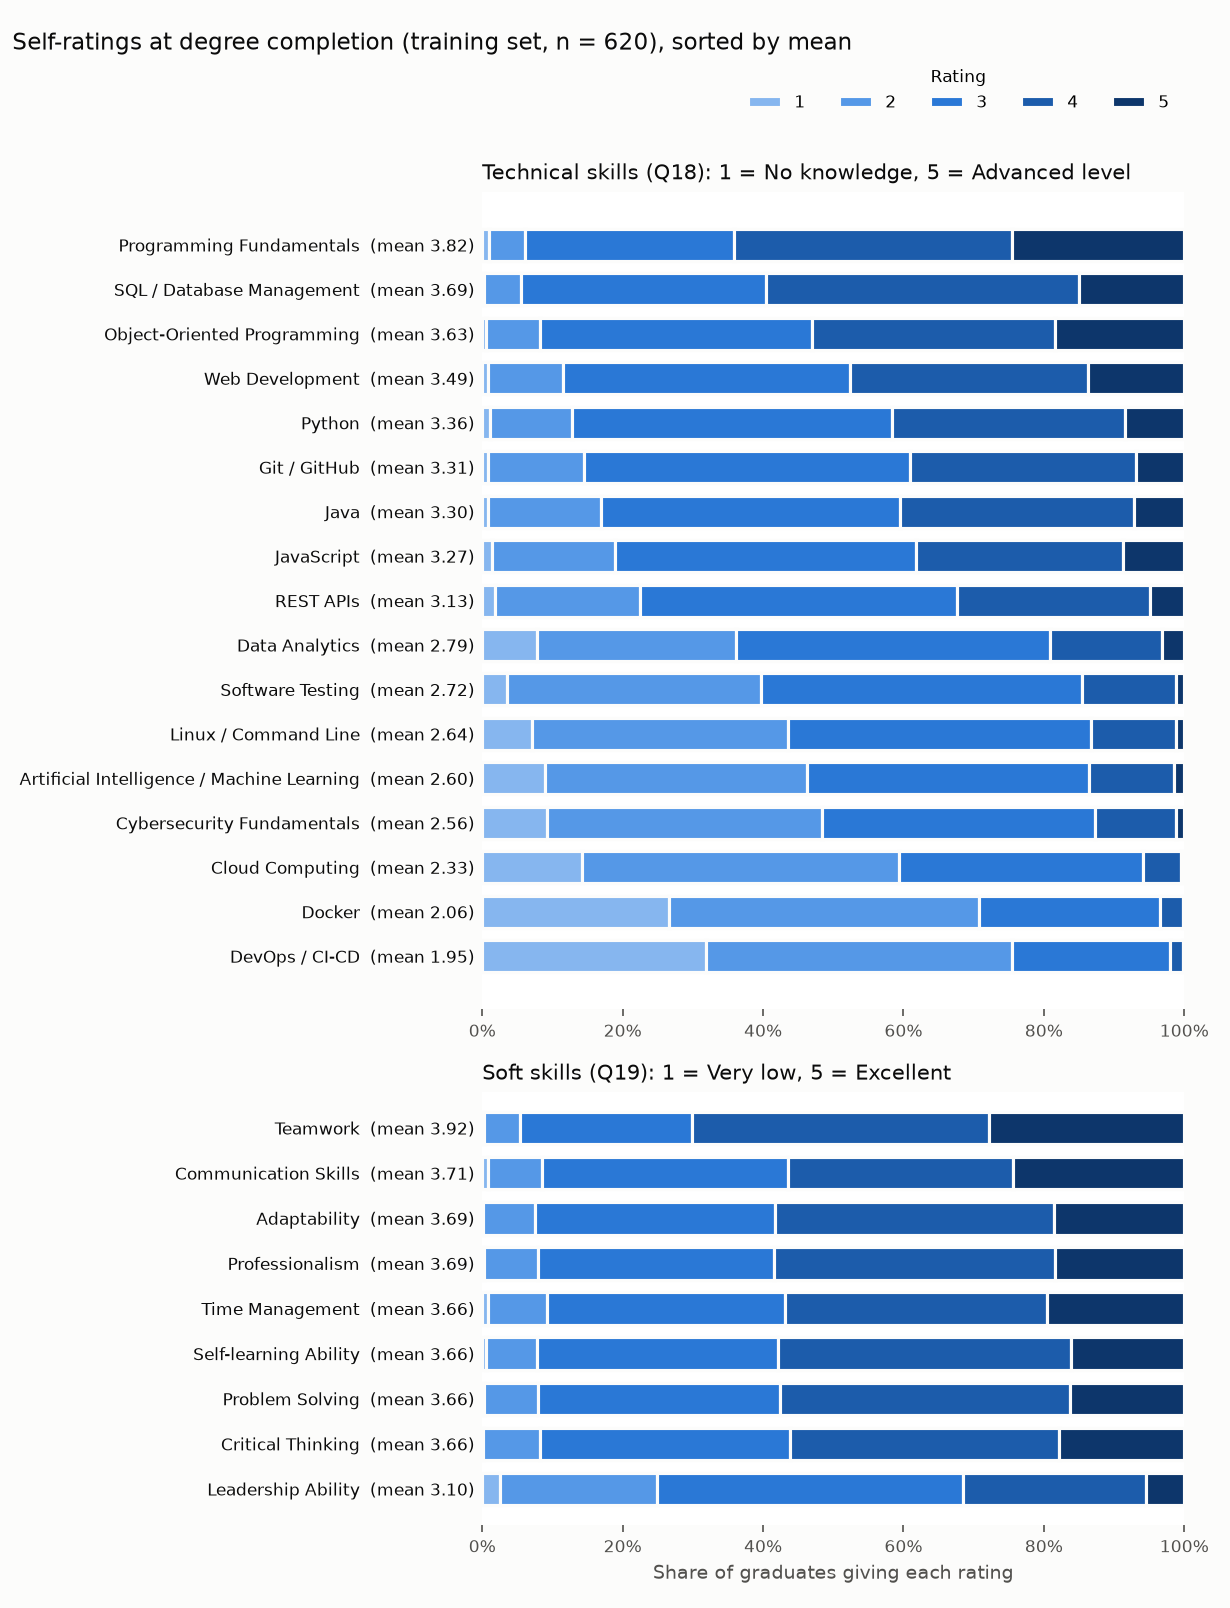

In [10]:
# ---- Distribution of the 26 skill ratings ---------------------------------------------------------------------
shares = eda_figures.likert_shares(train)
eda_figures.plot_likert(shares, len(train), TMP / "figures" / "likert.png")
show_png(TMP / "figures" / "likert.png", width=760)

> **What this shows:** Graduates rated themselves lowest on DevOps (1.95), Docker and cloud computing and highest on programming fundamentals (3.82); soft skills were rated higher and more evenly.

### 3.3 Reliability and factor structure of the skill scores

The model averages the technical items into one score and the soft items into another. That is justified if each
block is reliable (Cronbach's alpha >= 0.70) and dominated by one underlying factor (scree plot with parallel
analysis: factors above the dashed random-data line are retained).

,Block,N,KMO,Bartlett chi-square,Bartlett df,Factors (parallel analysis),Cronbach's alpha,alpha CI low,alpha CI high,McDonald's omega,AVE,Lowest loading,Highest loading
0,Technical (17 items),620,0.945,5584.004,136,3,0.925,0.916,0.933,0.926,0.429,0.454,0.752
1,Soft (9 items),620,0.948,2503.189,36,1,0.902,0.890,0.913,0.902,0.506,0.676,0.744


Discriminant validity: HTMT = 0.676 (below 0.85); sqrt(AVE) 0.655 technical and 0.711 soft, both above the 0.619 correlation between the two scores (Fornell-Larcker)


,Item,Block,Loading,Communality
0,Git / GitHub,Technical,0.752,0.565
1,Object-Oriented Programming,Technical,0.734,0.539
2,Java,Technical,0.727,0.529
3,Software Testing,Technical,0.721,0.520
4,Programming Fundamentals,Technical,0.718,0.515
5,SQL / Database Management,Technical,0.699,0.489
6,Python,Technical,0.699,0.489
7,JavaScript,Technical,0.676,0.456
8,REST APIs,Technical,0.670,0.449
9,Linux / Command Line,Technical,0.647,0.419


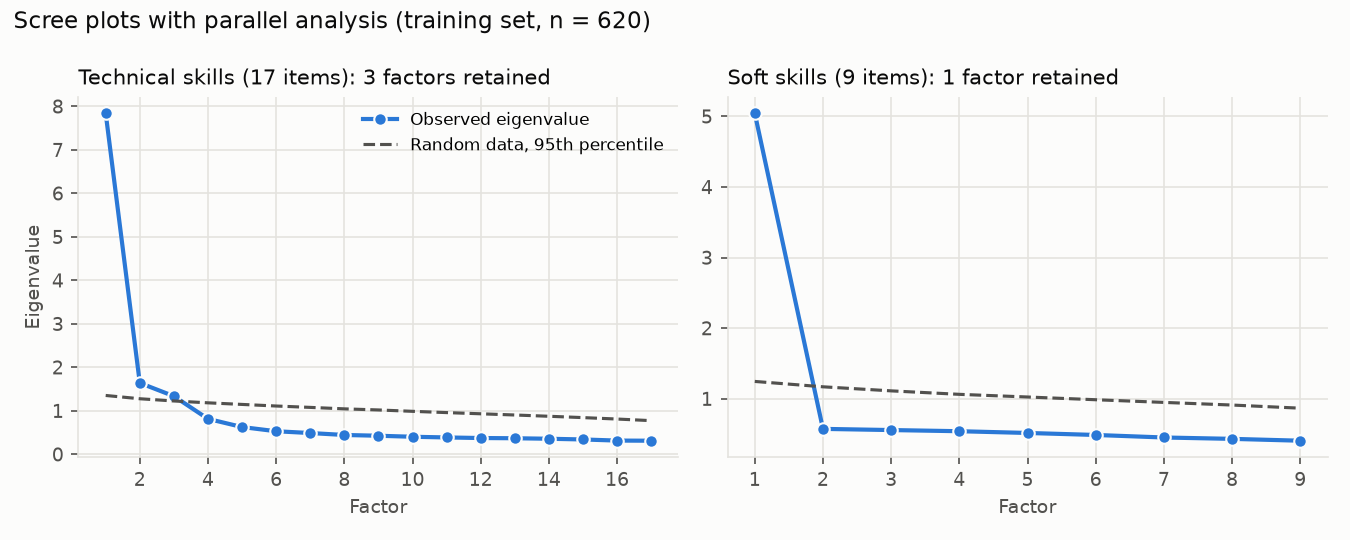

{'technical': '3 factor(s) retained; first factor explains 46.1%', 'soft': '1 factor(s) retained; first factor explains 56.0%'}


In [11]:
# ---- Reliability and validity of the two skill blocks (thesis Table E.3; core/construct_validity.py) -----------
# KMO and Bartlett: are the items correlated enough to factor?   alpha / omega: reliability (>= 0.70)
# AVE: variance the factor explains (>= 0.50 ideal);  HTMT < 0.85 and Fornell-Larcker: the two blocks are distinct
e3, e4, discriminant = construct_validity.block_validity(train)
show_table(e3[["block", "n", "kmo", "bartlett_chi2", "bartlett_df", "factors_parallel_analysis", "alpha", "alpha_lo",
            "alpha_hi", "omega", "ave", "loading_min", "loading_max"]].round(3))
print(f"Discriminant validity: HTMT = {discriminant['htmt']:.3f} (below 0.85); sqrt(AVE) "
      f"{discriminant['sqrt_ave_technical']:.3f} technical and {discriminant['sqrt_ave_soft']:.3f} soft, both above "
      f"the {discriminant['score_correlation']:.3f} correlation between the two scores (Fornell-Larcker)")
alpha = {"Technical (17 items)": float(e3.loc[0, "alpha"]), "Soft (9 items)": float(e3.loc[1, "alpha"])}

# ---- Item loadings on one factor per block (thesis Table E.4) -----------------------------------------------------
show_table(e4.round(3))

# ---- Scree plots with parallel analysis (same method and seed as thesis Table E.3) ------------------------------
scree = eda_figures.scree(train)
eda_figures.plot_scree(scree, TMP / "figures" / "scree.png")
show_png(TMP / "figures" / "scree.png")
print({block: f"{v['factors']} factor(s) retained; first factor explains {100 * v['eigenvalues'][0] / v['items']:.1f}%"
       for block, v in scree.items()})

> **What this shows:** Both blocks are highly reliable (alpha 0.925 and 0.902; KMO above 0.94) and clearly distinct from each other (HTMT 0.676). The technical block has a dominant first factor plus two small ones and an AVE of 0.43, below the 0.50 ideal, so the technical score summarises related abilities rather than one narrow skill - a limitation reported in the thesis.

### 3.4 How representative is the sample?

The sample compared with published Sri Lankan figures (University of Kelaniya, 2022). The published
figures describe another population, so this shows direction only.

In [12]:
# ---- Sample vs published figures (core/sample_comparison.py) ---------------------------------------------------
comparison = pd.DataFrame(sample_comparison.compare(grads))
comparison["measure"] = comparison["measure"].map(sample_comparison.LABELS)
show_table(comparison[["measure", "sample", "published", "difference", "source"]])

,Measure,Sample,Published,Difference,Source
0,Mean months to first job,5.0,8.0,-3.0,Univ. of Kelaniya (2022): Faculty of Computing & Technology
1,Employed graduates hired by completion (%),17.5,18.1,-0.6,Univ. of Kelaniya (2022): found work before/while studying
2,In an IT job at the survey (%),75.4,60.5,14.9,Univ. of Kelaniya (2022): all-faculty rate; IT expected higher
3,Median months (Kaplan-Meier),4.0,NaN,NaN,-


> **What this shows:** The share hired by completion matches the published figure closely; the sample was more often employed and found work faster, as expected for IT graduates and for a voluntary survey. The results describe this sample, not all Sri Lankan IT graduates.

<a id="s4"></a>

## 4. Time to first IT job

### 4.1 Kaplan-Meier curve

The Kaplan-Meier estimator gives the share who had found an IT job by each month, using the graduates still
searching correctly. The row beneath the chart is the number still being followed at each time.

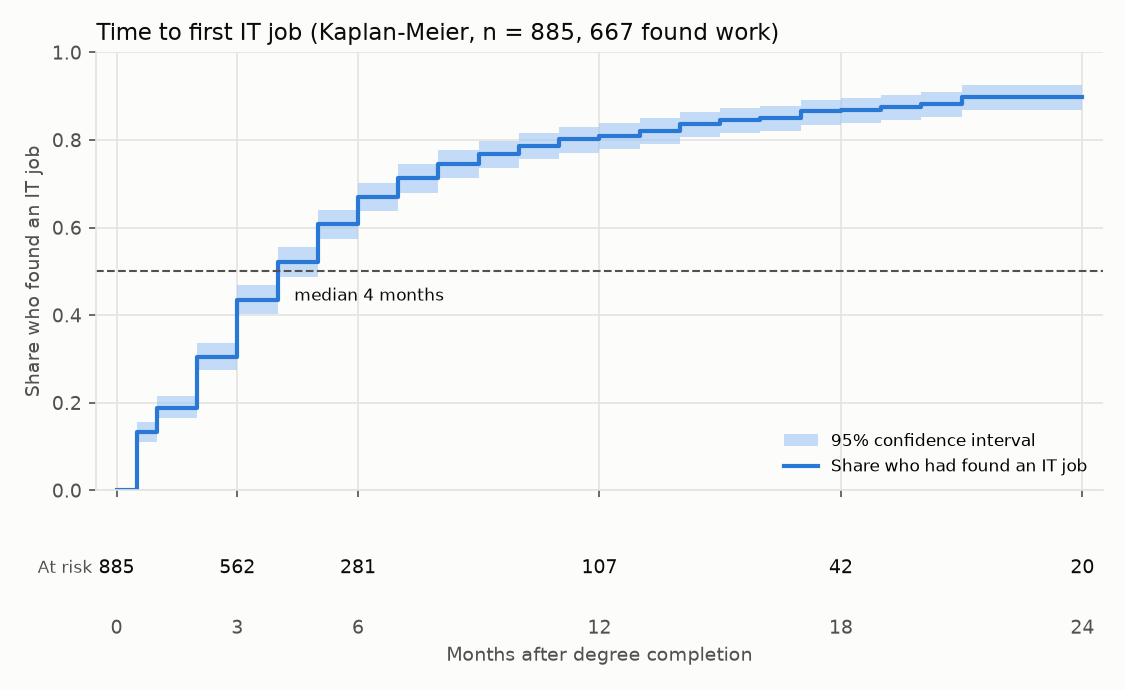

Median time to first IT job: 4 months
Share employed by 3 / 6 / 12 / 24 months: 43.6% / 67.0% / 80.9% / 89.8%


In [13]:
# ---- All evaluation figures at once (core/evaluation_figures.py), written to the scratch folder -----------------
# This draws: Kaplan-Meier with numbers at risk, AFT fit, Schoenfeld plot, fairness and robustness charts.
# Fairness and robustness are drawn from the saved reports - the test set is not evaluated again.
ev = evaluation_figures.run(out_dir=TMP)

show_png(TMP / "figures" / "km_at_risk.png")
km = ev["km"]
print(f"Median time to first IT job: {km['median_months']:g} months")
print("Share employed by 3 / 6 / 12 / 24 months:",
      " / ".join(f"{100 * v:.1f}%" for v in km["employed_by"].values()))

> **What this shows:** Half the graduates had a first IT job within 4 months and about 90% within two years. Few graduates are followed beyond 18 months, so the right end of the curve is less certain.

### 4.2 Differences between groups (log-rank tests, training set)

,Group,Level,N,Employed by 6 m,Median (months),Log-rank p
0,Internship completed,no,112,53.3%,6.0,0.0033
1,Internship completed,yes,508,68.1%,4.0,0.0033
2,Any certification,1 or more,370,68.8%,4.0,0.0841
3,Any certification,none,250,60.3%,5.0,0.0841
4,GPA 3.0 or higher,3.0+,411,73.9%,4.0,0.0000
5,GPA 3.0 or higher,below 3.0,209,48.1%,7.0,0.0000
6,Portfolio before completion,no,356,61.2%,5.0,0.0059
7,Portfolio before completion,yes,264,71.2%,4.0,0.0059
8,Institution type,Foreign-affiliated,275,67.3%,4.0,0.8370
9,Institution type,Non-state,140,61.6%,5.0,0.8370


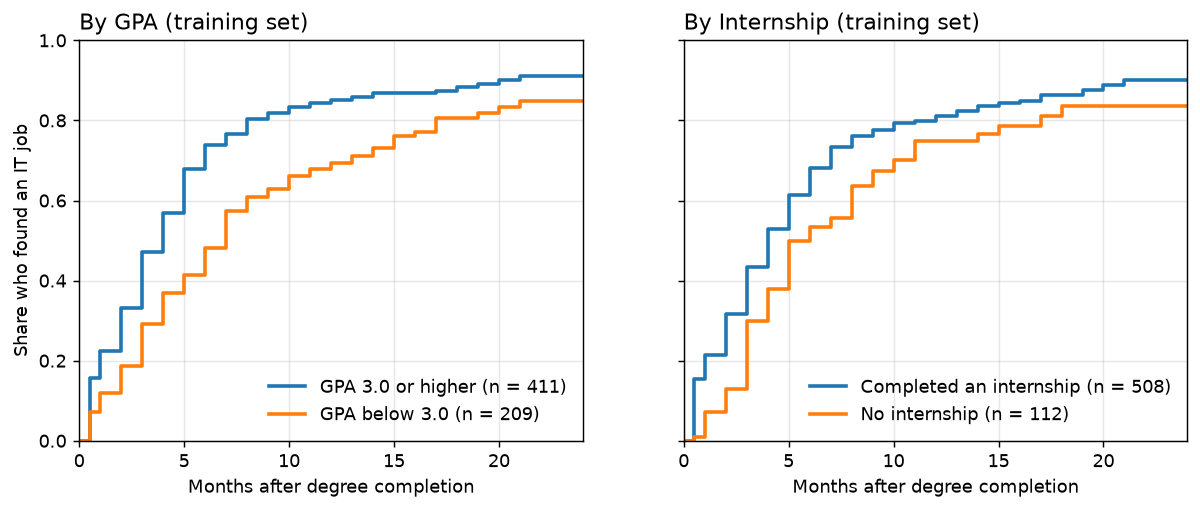

In [14]:
# ---- Log-rank tests by group (core/thesis_results.py) -----------------------------------------------------------
rows = []
for g in thesis_results.km_groups(train):
    for level, v in g["levels"].items():
        rows.append({"Group": g["group"], "Level": level, "n": v["n"], "Employed by 6 m": f"{v['employed_by_6m']:.1%}",
                     "Median (months)": v.get("median_months"), "Log-rank p": round(g["p"], 4)})
show_table(pd.DataFrame(rows))

# ---- Kaplan-Meier curves for the two clearest differences: GPA and internship -----------------------------------
from lifelines import KaplanMeierFitter
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
splits_by = {"GPA": np.where(train["gpa"] >= 3.0, "GPA 3.0 or higher", "GPA below 3.0"),
             "Internship": np.where(train["internship_completed"] == "yes", "Completed an internship", "No internship")}
for ax, (title, groups) in zip(axes, splits_by.items()):
    for level in sorted(set(groups)):
        sel = groups == level
        kmf = KaplanMeierFitter().fit(train.loc[sel, "duration_months"], train.loc[sel, "event"], label=f"{level} (n = {sel.sum()})")
        ax.step(kmf.survival_function_.index, 1 - kmf.survival_function_.iloc[:, 0], where="post", linewidth=2,
                label=kmf._label)
    ax.set_xlim(0, 24); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
    ax.set_title(f"By {title} (training set)", loc="left"); ax.set_xlabel("Months after degree completion")
    ax.legend(frameon=False, loc="lower right")
axes[0].set_ylabel("Share who found an IT job")
show_fig(fig)

> **What this shows:** GPA of 3.0 or higher (p < 0.001), an internship (p = 0.003) and a portfolio (p = 0.006) were linked to a faster search; institution type (p = 0.84) and degree group (p = 0.47) were not.

### 4.3 Competing paths

Some graduates took another path first (a non-IT job, self-employment or further studies). The cumulative incidence
treats that as a competing outcome; 1 - Kaplan-Meier (dashed) would treat it as censoring.

,It role (cumulative incidence),It role (1 - kaplan-meier),Another path (cumulative incidence)
3,0.400,0.405,0.031
6,0.637,0.658,0.054
12,0.778,0.819,0.065
24,0.870,0.924,0.065


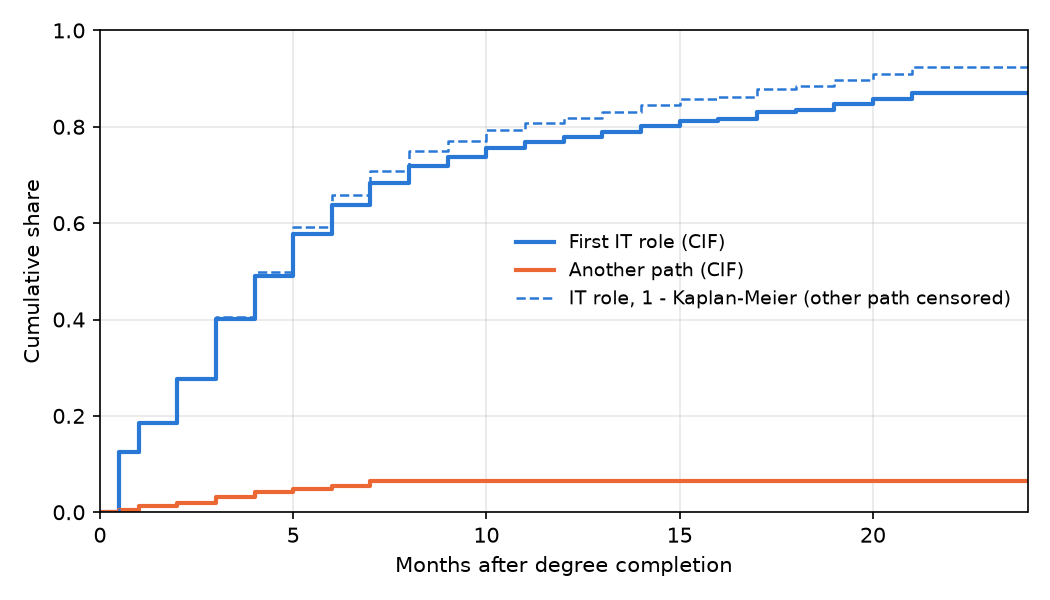

In [15]:
# ---- Competing risks (core/competing.py; saved result) ----------------------------------------------------------
summary = json.loads((ART / "run_summary.json").read_text(encoding="utf-8"))
comp_risks = summary["robustness"]["competing"]
show_table(pd.DataFrame({"IT role (cumulative incidence)": comp_risks["cif_it"],
                      "IT role (1 - Kaplan-Meier)": comp_risks["one_minus_km"],
                      "Another path (cumulative incidence)": comp_risks["cif_other_path"]}).rename_axis("Months").round(3))
show_png(FIG / "competing_cif.png", width=760)

> **What this shows:** Taking another path first (non-IT job, further study) was rare (6.5% by 12 months), so treating it as censoring changes the estimates only slightly (81.9% vs 77.8% in IT work by 12 months).

<a id="s5"></a>

## 5. The fixed train / validation / test split

Each graduate has exactly **one** role, assigned once before any modelling (`core/splits.py`), stratified by event and
institution type with a fixed seed:

* **train (70%)** - every model is fitted here, including preprocessing;
* **validation (15%)** - hyperparameters are tuned and models compared here;
* **test (15%)** - locked; the selected model was evaluated on it **once**.

No graduate is reused across roles (the supervisor's rule), so cross-validation is not used.

,Split,Graduates,Events,Still searching,Share censored
0,Train,620,467,153,24.7%
1,Validation,133,100,33,24.8%
2,Test,132,100,32,24.2%


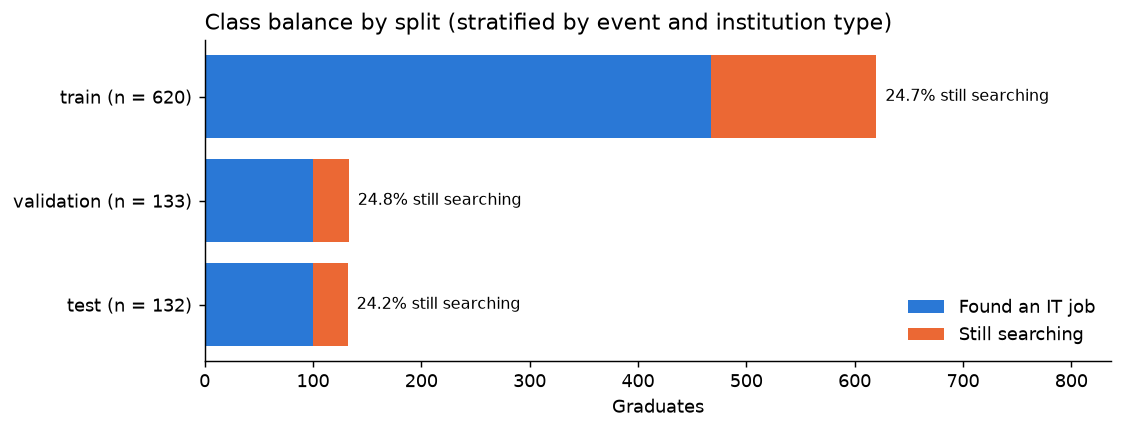

In [16]:
# ---- Size, events and censoring per split ----------------------------------------------------------------------
with_split = splits.attach(grads)
by_split = splits.summary(with_split)
by_split["still searching"] = by_split["graduates"] - by_split["events"]
by_split["share censored"] = (by_split["still searching"] / by_split["graduates"]).map("{:.1%}".format)
show_table(by_split)

# ---- Class balance in each split: the stratified split keeps about the same share still searching ---------------
fig, ax = plt.subplots(figsize=(9, 3.2))
y = np.arange(len(by_split))
found, searching = by_split["events"].to_numpy(), by_split["still searching"].to_numpy()
ax.barh(y, found, color="#2a78d6", label="Found an IT job")
ax.barh(y, searching, left=found, color="#eb6834", label="Still searching")
for i, (f, s) in enumerate(zip(found, searching)):        # share still searching at the end of each bar
    ax.annotate(f"{s / (f + s):.1%} still searching", (f + s, i), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9)
ax.set_yticks(y, [f"{r} (n = {n})" for r, n in zip(by_split["split"], by_split["graduates"])])
ax.invert_yaxis()
ax.set_xlim(0, by_split["graduates"].max() * 1.35)
ax.set_xlabel("Graduates")
ax.set_title("Class balance by split (stratified by event and institution type)", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
show_fig(fig)

> **What this shows:** The stratified split kept the share still searching almost identical in every set (24.2-24.8%), so the sets are comparable.

### 5.1 Sample characteristics by split (thesis Table E.1)

The three sets should look alike. They do on most characteristics; the test set had more internships and a shorter
median search, one reason its results differ from validation (section 10).

In [17]:
# ---- Characteristics of each split, and all graduates (core/construct_validity.py) -------------------------------
show_table(construct_validity.split_characteristics(construct_validity.with_scores(with_split)))

,Train,Validation,Test,All
n,620,133,132,885
events,467,100,100,667
censored,24.7%,24.8%,24.2%,24.6%
women,33.4%,29.3%,36.4%,33.2%
state / non-state / foreign,33.1% / 22.6% / 44.4%,33.1% / 22.6% / 44.4%,32.6% / 22.7% / 44.7%,33.0% / 22.6% / 44.4%
GPA mean (SD),3.09 (0.37),3.06 (0.41),3.07 (0.37),3.08 (0.37)
internship completed,81.9%,77.4%,90.9%,82.6%
internship months median (IQR),6 (3-6),6 (3-6),6 (4-6),6 (3-6)
certifications median (IQR),1 (0-2),1 (0-2),1 (0-1),1 (0-2)
projects median (IQR),3 (1-4),2 (1-4),2 (1-4),2 (1-4)


> **What this shows:** The sets are alike on most characteristics. The test set had more internships (90.9% vs 81.9%) and a shorter median search (3 vs 4 months) - one reason the model, calibrated on the training set, under-predicts employment on the test set (section 10).

<a id="s6"></a>

## 6. Training and hyperparameter tuning

Seven models from four families are trained on the training set:

| Family | Models | Tuned |
|---|---|---|
| Cox proportional hazards | Cox PH | ridge penalty |
| Penalised Cox | Elastic Net Cox | penalty strength and L1 ratio |
| Accelerated failure time | Weibull, log-normal, log-logistic | distribution chosen by AIC on the training set |
| Neural network | DeepSurv | width, depth, dropout, learning rate |

For each tuned model, every setting is fitted on the training set and scored on the validation set; the best is
kept. This cell runs the full training and tuning, so it takes a few minutes.

In [18]:
# ---- Train and tune every model on the training set, score on validation (core/evaluate.py) --------------------
metrics_rows, valid_predictions, chosen_settings = evaluate.holdout(train, valid)

show_table(pd.DataFrame([{"Model": evaluate.LABELS[m], "Chosen setting": json.dumps(p)}
                      for m, p in chosen_settings.items()]))

,Model,Chosen setting
0,Cox PH,"{""penalizer"": 0.5}"
1,Elastic Net Cox,"{""alpha"": 0.005, ""l1_ratio"": 0.1}"
2,DeepSurv,"{""width"": 32, ""layers"": 1, ""dropout"": 0.3, ""lr"": 0.01}"
3,AFT (best by AIC),"{""distribution"": ""lognormal""}"


> **What this shows:** Each tuned model's best setting was found on the validation set; the AFT distribution was chosen by AIC on the training set, as fixed in advance.

### 6.1 Every tuning configuration

The full grid behind the chosen settings: 4 Cox, 15 Elastic Net and 24 DeepSurv settings, plus the three AFT
distributions. The last column checks that the setting chosen here is the one recorded by the main analysis.

In [19]:
# ---- Every setting with its validation Uno's C (core/tuning_results.py) -----------------------------------------
tuning = tuning_results.run(out_dir=TMP)
show_table(tuning[tuning["chosen"]][["label", "params", "aic", "uno_c", "matches_main_analysis"]].round(3))

# Spread of the validation C across settings: small spreads mean the comparison does not hinge on one setting
spread = tuning.groupby("model")["uno_c"].agg(["min", "max", "count"])
spread["range"] = spread["max"] - spread["min"]
show_table(spread.round(3))

,Model,Setting,AIC,Uno's C,Matches main analysis
3,Cox PH,"{""penalizer"": 0.5}",NaN,0.667,True
4,Elastic Net Cox,"{""alpha"": 0.005, ""l1_ratio"": 0.1}",NaN,0.665,True
38,DeepSurv,"{""width"": 32, ""layers"": 1, ""dropout"": 0.3, ""lr"": 0.01}",NaN,0.679,True
44,AFT,"{""distribution"": ""lognormal""}",2724.83,0.693,True


,Lowest,Highest,Settings,Range
AFT (best by AIC),0.655,0.693,3,0.038
Elastic Net Cox,0.637,0.665,15,0.029
Cox PH,0.666,0.667,4,0.001
DeepSurv,0.568,0.679,24,0.111


> **What this shows:** Cox PH barely changed across settings (0.666-0.667); Elastic Net varied more and DeepSurv most (0.568-0.679). Every chosen setting matches the main analysis, so the model comparison does not depend on a lucky setting.

### 6.2 DeepSurv training and early stopping

DeepSurv holds out 20% of the training graduates to monitor its loss and stops when that loss stops improving,
keeping the best weights. The two losses are on different scales, so compare their **trends**.

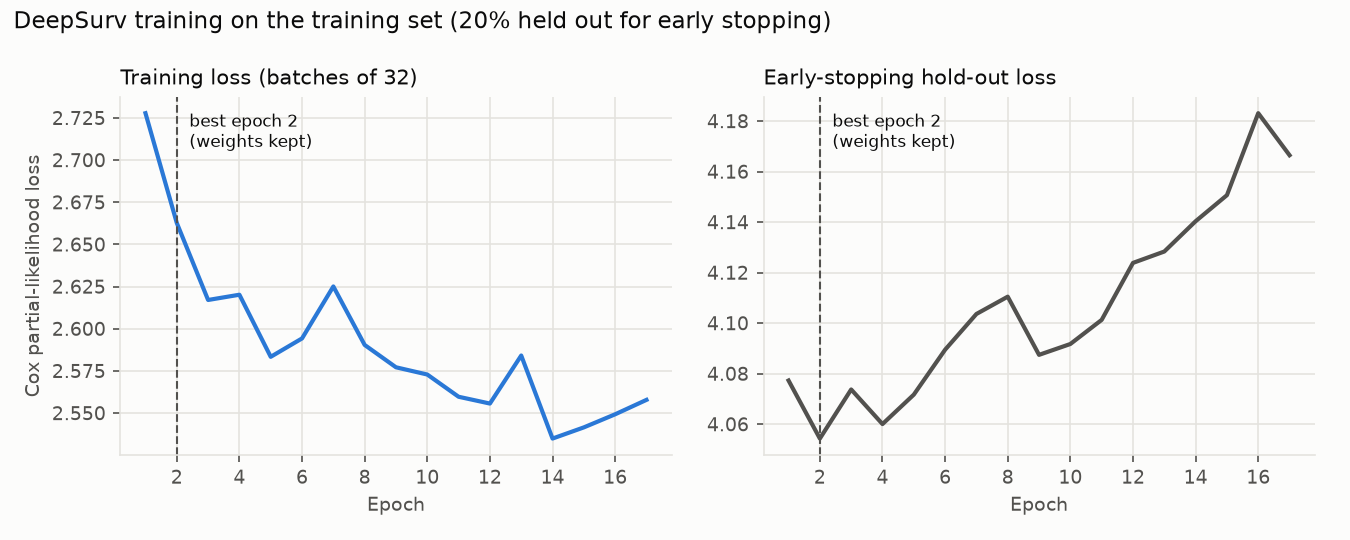

Best epoch 2 of 17; training stopped 15 epochs later and the best weights were kept (overfitting control)


In [20]:
# ---- DeepSurv training and early-stopping loss (core/deepsurv_curves.py) ----------------------------------------
ds = deepsurv_curves.run(out_dir=TMP)
show_png(TMP / "figures" / "deepsurv_loss.png")
print(f"Best epoch {ds['best_epoch']} of {ds['epochs_run']}; training stopped {ds['patience']} epochs later "
      "and the best weights were kept (overfitting control)")

> **What this shows:** The training loss keeps falling, but the hold-out loss is lowest at epoch 2 and then rises: the network starts to overfit almost at once. Early stopping keeps the epoch-2 weights - a sign that this data holds limited signal for a neural network.

<a id="s7"></a>

## 7. Model comparison and selection

Metrics on the **validation set**:

* **Uno's C** (primary) - how well the model ranks who finds work first (0.5 = chance, 1 = perfect);
* **integrated Brier score (IBS)** - overall error of the predicted probabilities (lower is better);
* **calibration error** - predicted vs observed share employed by 3, 6 and 12 months.

**Selection rule, fixed in advance:** highest validation Uno's C; if another candidate is within 0.02, prefer the
simpler model (Cox PH = AFT < Elastic Net Cox < DeepSurv), then the better calibrated.

In [21]:
# ---- Summarise the validation results and apply the pre-set selection rule -------------------------------------
comparison_table, calibration = evaluate.summarise_validation(pd.DataFrame(metrics_rows), valid_predictions)
cols = [c for c in ["label", "candidate", "uno_c_mean", "uno_c_lo", "uno_c_hi", "harrell_c_mean", "ibs_mean",
                    "cal_err_3m_mean", "cal_err_6m_mean", "cal_err_12m_mean"] if c in comparison_table]
show_table(comparison_table[cols].round(3))

selected, reason = evaluate.select_model(comparison_table)
print("Selected:", evaluate.LABELS[selected], "-", reason)

,Model,Candidate,Uno's C,95% CI low,95% CI high,Harrell's C,IBS,Calibration error 3 m,Calibration error 6 m,Calibration error 12 m
0,Cox PH,True,0.667,0.602,0.728,0.666,0.179,0.110,0.092,0.035
1,Elastic Net Cox,True,0.665,0.607,0.723,0.664,0.175,0.132,0.111,0.056
2,AFT Weibull,False,0.655,0.592,0.712,0.653,0.179,0.106,0.091,0.024
3,AFT Log-Normal,False,0.693,0.636,0.745,0.692,0.171,0.126,0.118,0.088
4,AFT Log-Logistic,False,0.687,0.628,0.740,0.686,0.171,0.093,0.100,0.079
5,AFT (best by AIC),True,0.693,0.636,0.745,0.692,0.171,0.126,0.118,0.088
6,DeepSurv,True,0.679,0.621,0.741,0.676,0.175,0.100,0.113,0.068


Selected: AFT (best by AIC) - highest mean Uno's C (0.693); it was also the simplest / best-calibrated of the models within the margin


> **What this shows:** AFT log-normal ranked graduates best (0.693). Log-logistic (0.687) and DeepSurv (0.679) were within the 0.02 margin; the rule prefers the simpler, better-calibrated model, so AFT log-normal was selected. The intervals overlap, so the ranking of models should not be over-read.

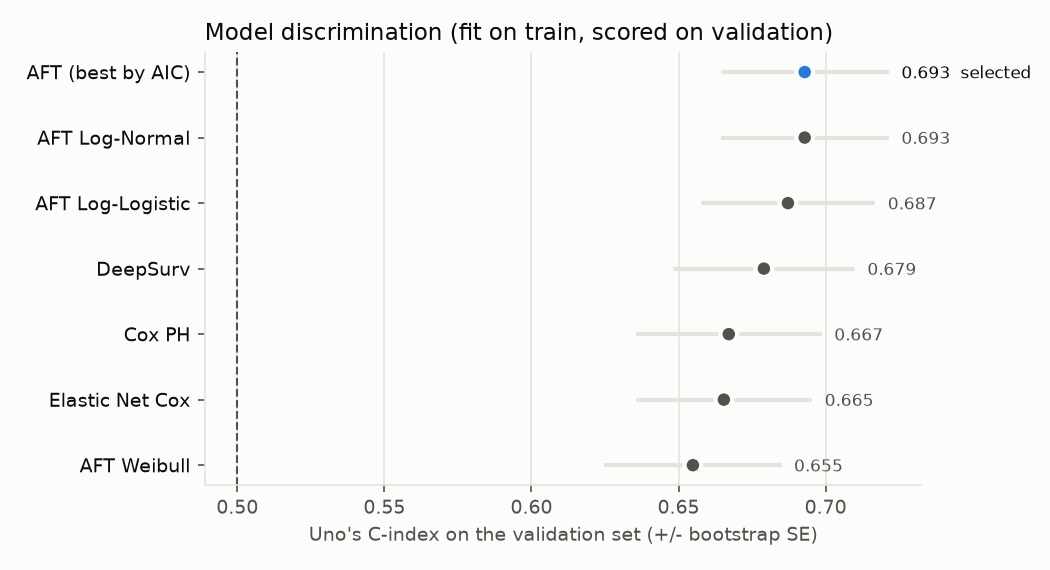

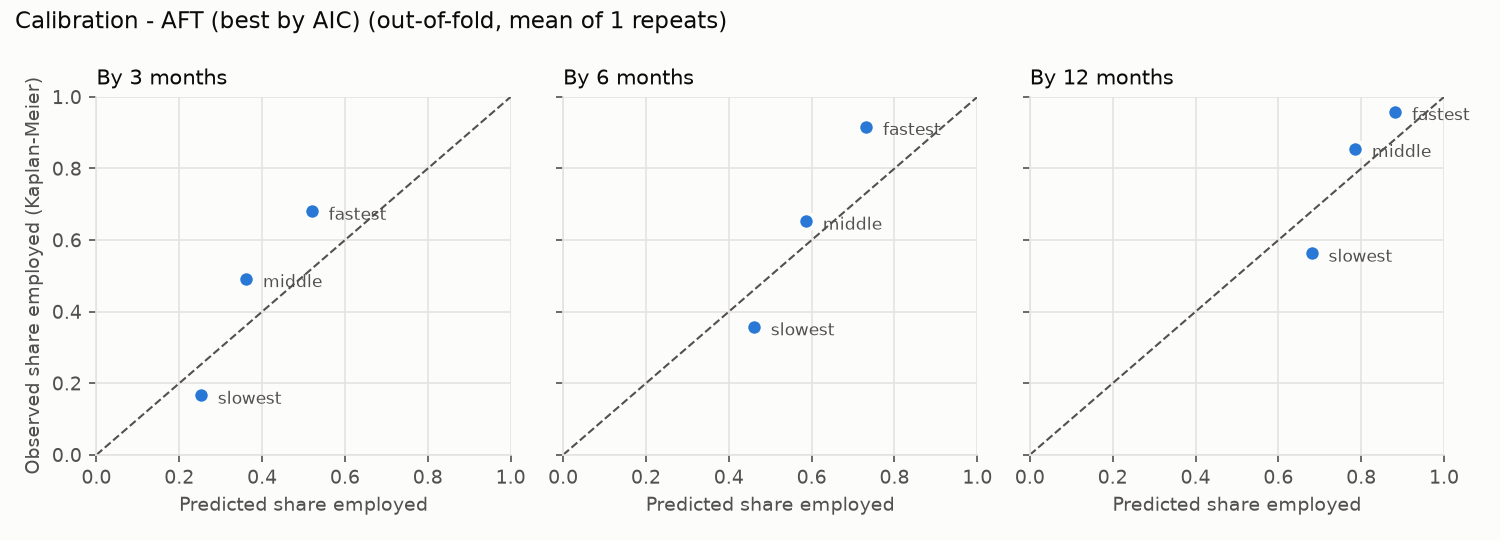

In [22]:
# ---- Validation C-index of every model, and calibration of the selected model -----------------------------------
evaluate.plot_comparison(comparison_table, selected, TMP / "figures" / "model_comparison.png")
show_png(TMP / "figures" / "model_comparison.png", width=760)

evaluate.plot_calibration(calibration, selected, TMP / "figures" / "calibration_selected.png")
show_png(TMP / "figures" / "calibration_selected.png")

<a id="s8"></a>

## 8. Model checks

### 8.1 Does the log-normal distribution fit?

The mean predicted share employed under each AFT distribution, against the observed Kaplan-Meier curve (training set).

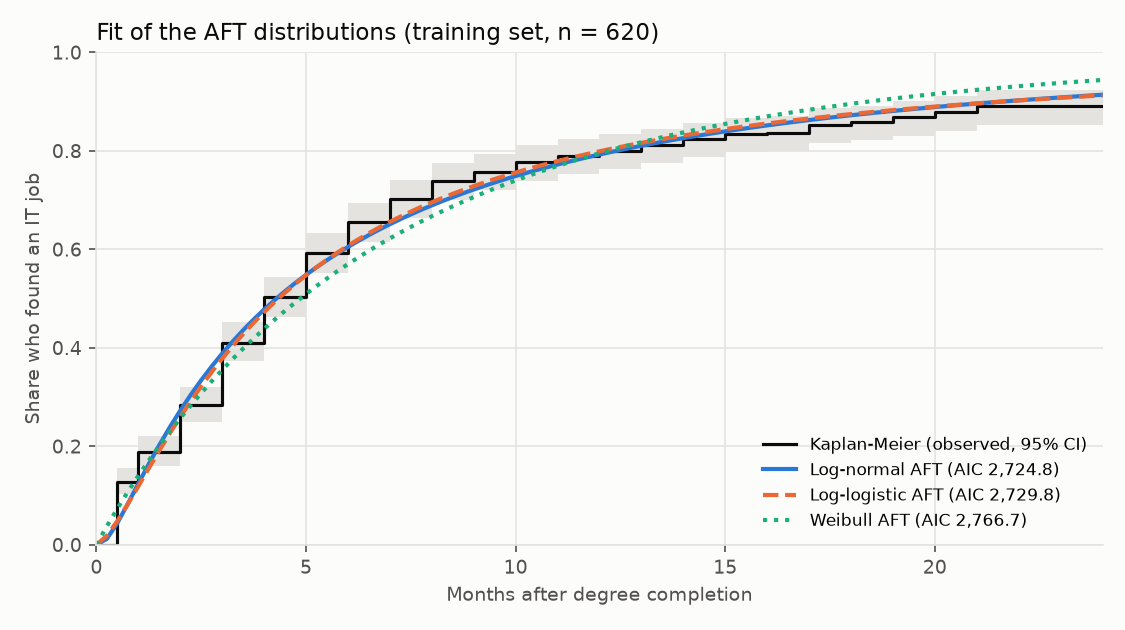

,Aic,Largest gap,Mean gap
lognormal,2724.830,0.083,0.020
loglogistic,2729.786,0.079,0.020
weibull,2766.719,0.084,0.036


In [23]:
# ---- AFT distribution fit (drawn by evaluation_figures.run in section 4) -----------------------------------------
show_png(TMP / "figures" / "aft_fit.png")
show_table(pd.DataFrame(ev["aft_fit"]).T.rename(columns={"aic": "AIC", "mean_abs_gap": "mean gap", "max_abs_gap": "largest gap"})
        .sort_values("AIC").round(3))

> **What this shows:** Log-normal and log-logistic follow the observed curve closely (about 2 points on average); Weibull rises too slowly in the first year. Log-normal had the lowest AIC, the pre-set rule.

### 8.2 Proportional-hazards check (Cox model)

Scaled Schoenfeld residuals: a flat smoothed line means a factor's effect does not change over time. All tests have
p > 0.10, so the assumption holds for the Cox models. (The selected AFT model does not need this assumption.)

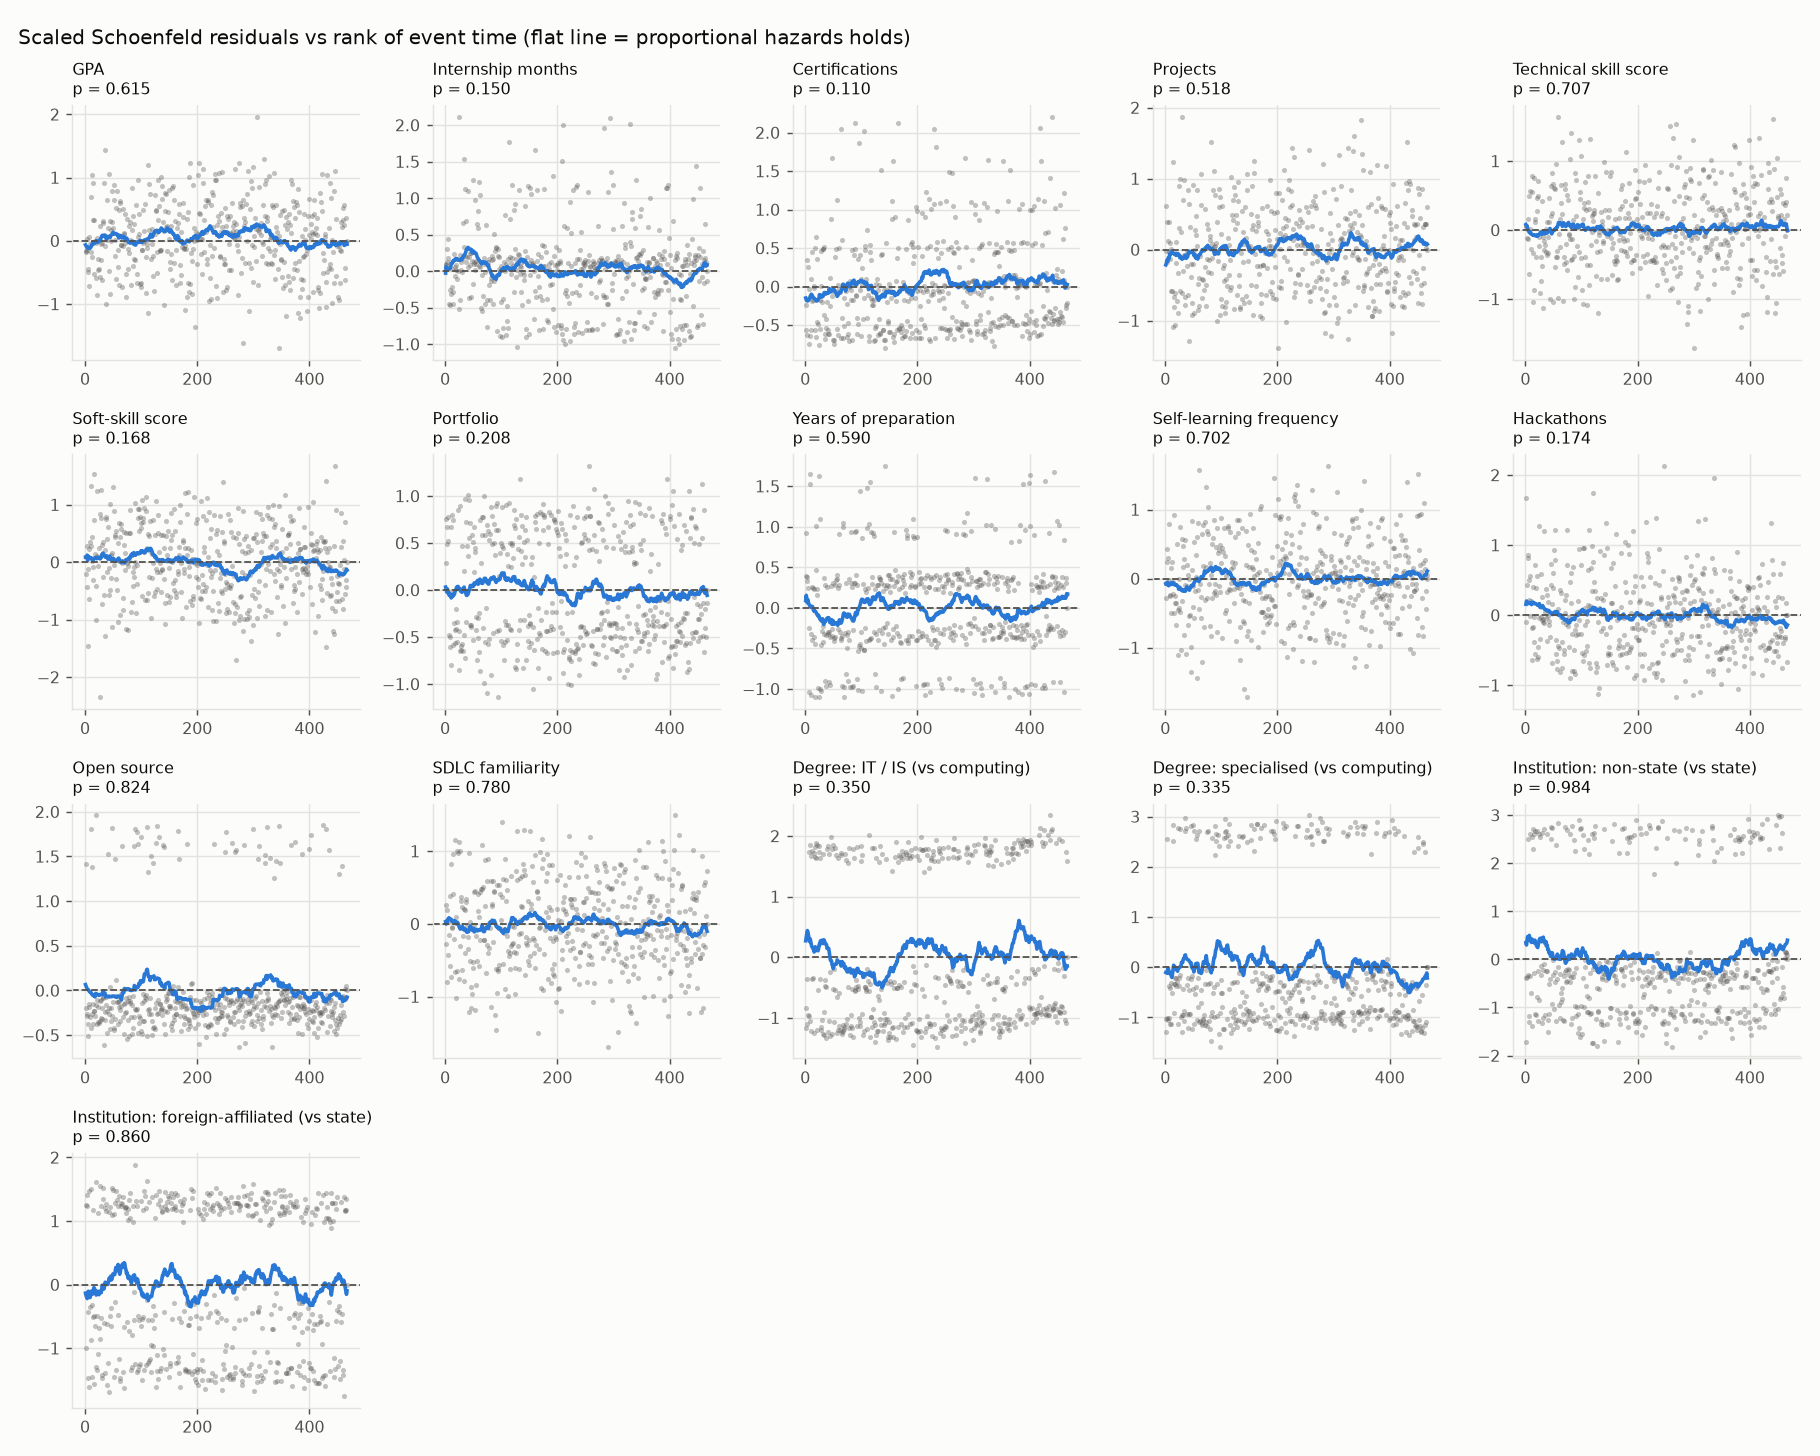

Smallest Schoenfeld p-value: 0.11


In [24]:
# ---- Schoenfeld residuals (drawn by evaluation_figures.run) -----------------------------------------------------
show_png(TMP / "figures" / "schoenfeld_labelled.png")
print("Smallest Schoenfeld p-value:", round(min(ev["schoenfeld_p"].values()), 3))

> **What this shows:** No smoothed line trends away from zero and every p-value is above 0.10, so the Cox models' proportional-hazards assumption holds.

### 8.3 Which factors are associated with a shorter search? (RQ1)

The selected model is refitted on the training set with the chosen settings. Its coefficients are shown as **time
ratios** per one standard deviation: below 1 means a shorter search. p-values are also corrected for testing 16
coefficients (Holm).

,Time ratio,95% ci low,95% ci high,P,Holm p
GPA,0.804,0.702,0.920,0.001,0.022
Internship months,0.844,0.761,0.936,0.001,0.021
Institution: non-state (vs state),0.863,0.653,1.139,0.298,1.000
Degree: specialised (vs computing),0.898,0.690,1.168,0.423,1.000
Degree: IT / IS (vs computing),0.913,0.725,1.149,0.437,1.000
Technical skill score,0.919,0.785,1.077,0.298,1.000
Certifications,0.948,0.858,1.048,0.300,1.000
Portfolio,0.949,0.848,1.062,0.359,1.000
Institution: foreign-affiliated (vs state),0.956,0.757,1.206,0.703,1.000
Hackathons,0.957,0.852,1.074,0.453,1.000


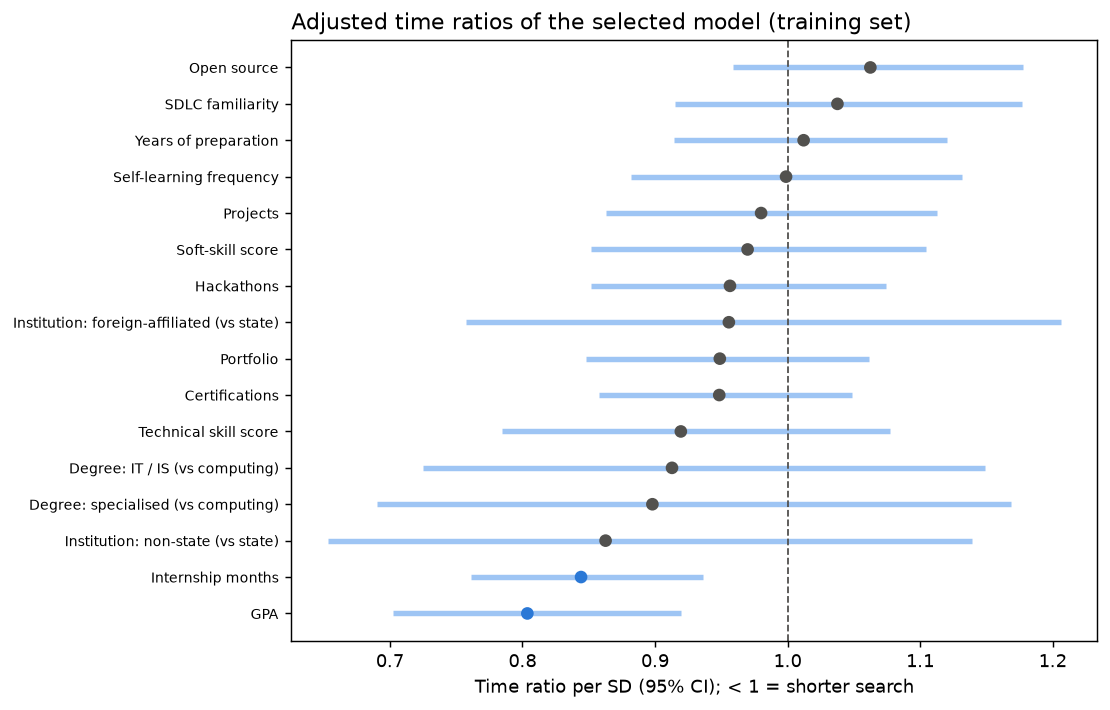

Clearly associated (CI excludes 1): GPA, Internship months


In [25]:
# ---- Fit the final model on the training set and extract time ratios --------------------------------------------
final = evaluate.fit_final(train, selected, chosen_settings)
coef = final["model"].coefficients.copy()            # AFT coefficients on log(time), per SD of each input

ratios = pd.DataFrame({"time ratio": np.exp(coef["coef"]), "95% CI low": np.exp(coef["lower"]),
                       "95% CI high": np.exp(coef["upper"]), "p": coef["p"]})

# Holm correction for the 16 coefficients
order = ratios["p"].sort_values().index
k = len(order)
holm = np.minimum(1, np.maximum.accumulate(ratios.loc[order, "p"].to_numpy() * (k - np.arange(k))))
ratios.loc[order, "Holm p"] = holm
ratios = ratios.sort_values("time ratio")
show_table(ratios.round(3))

# ---- Forest plot of the time ratios -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(ratios))
clear = (ratios["95% CI high"] < 1) | (ratios["95% CI low"] > 1)
ax.hlines(y, ratios["95% CI low"], ratios["95% CI high"], color="#9ec5f4", linewidth=3)
ax.scatter(ratios["time ratio"], y, color=np.where(clear, "#2a78d6", "#52514e"), zorder=3)
ax.axvline(1, color="#52514e", linestyle="--", linewidth=1)
ax.set_yticks(y, [evaluation_figures.LABELS.get(f, f) for f in ratios.index], fontsize=8)   # readable names
ax.set_xlabel("Time ratio per SD (95% CI); < 1 = shorter search")
ax.set_title("Adjusted time ratios of the selected model (training set)", loc="left")
show_fig(fig, width=760)
print("Clearly associated (CI excludes 1):", ", ".join(evaluation_figures.LABELS.get(f, f) for f in ratios.index[clear]))

> **What this shows:** Only GPA (time ratio 0.80: about 20% shorter search per 0.4 GPA points) and internship experience (0.84: about 16% shorter per 3.5 months) have intervals that exclude 1, and both stay significant after Holm correction. Every other factor's interval includes 'no effect'.

**Thesis Table 5.3** reports the same factors from two angles: the Cox hazard ratio (above 1 = finding work sooner)
and the AFT time ratio (below 1 = a shorter search). The Cox model here is unpenalised and fitted on the training set,
with the same scaling. Both point the same way for every clearly associated factor.

In [26]:
# ---- Unpenalised Cox model on the training set: hazard ratios per SD ----------------------------------------------
cox_pre, cox_model = evaluate.fit_all(train, {"penalizer": 0.0}, None, "cox_ph", evaluate.SEED)
cox = cox_model.coefficients
r2 = lambda x: f"{float(f'{x:.3f}'):.2f}"   # round to 3 decimals, then 2 - the convention used in the thesis tables
table_53 = pd.DataFrame({
    "Cox HR (95% CI); > 1 = sooner": [f"{np.exp(r.coef):.2f} ({np.exp(r.lower):.2f}-{np.exp(r.upper):.2f})" for r in cox.itertuples()],
    "AFT time ratio (95% CI); < 1 = sooner": [f"{r2(ratios.loc[f, 'time ratio'])} ({r2(ratios.loc[f, '95% CI low'])}-"
                                              f"{r2(ratios.loc[f, '95% CI high'])})" for f in cox.index],
}, index=[evaluation_figures.LABELS.get(f, f) for f in cox.index])
show_table(table_53)

,Cox hr (95% ci); > 1 = sooner,Aft time ratio (95% ci); < 1 = sooner
GPA,1.24 (1.10-1.40),0.80 (0.70-0.92)
Internship months,1.12 (1.03-1.23),0.84 (0.76-0.94)
Certifications,1.09 (1.00-1.19),0.95 (0.86-1.05)
Projects,1.07 (0.95-1.20),0.98 (0.86-1.11)
Technical skill score,1.13 (0.98-1.31),0.92 (0.79-1.08)
Soft-skill score,0.98 (0.87-1.12),0.97 (0.85-1.10)
Portfolio,1.02 (0.92-1.13),0.95 (0.85-1.06)
Years of preparation,1.01 (0.92-1.11),1.01 (0.92-1.12)
Self-learning frequency,1.01 (0.90-1.13),1.00 (0.88-1.13)
Hackathons,1.01 (0.91-1.11),0.96 (0.85-1.07)


> **What this shows:** The Cox hazard ratios and the AFT time ratios tell the same story: GPA and internship are the clear factors (HR above 1 and time ratio below 1 both mean a faster search).

<a id="s9"></a>

## 9. Diagnostics (training and validation sets only)

### 9.1 Learning curve - would more respondents help?

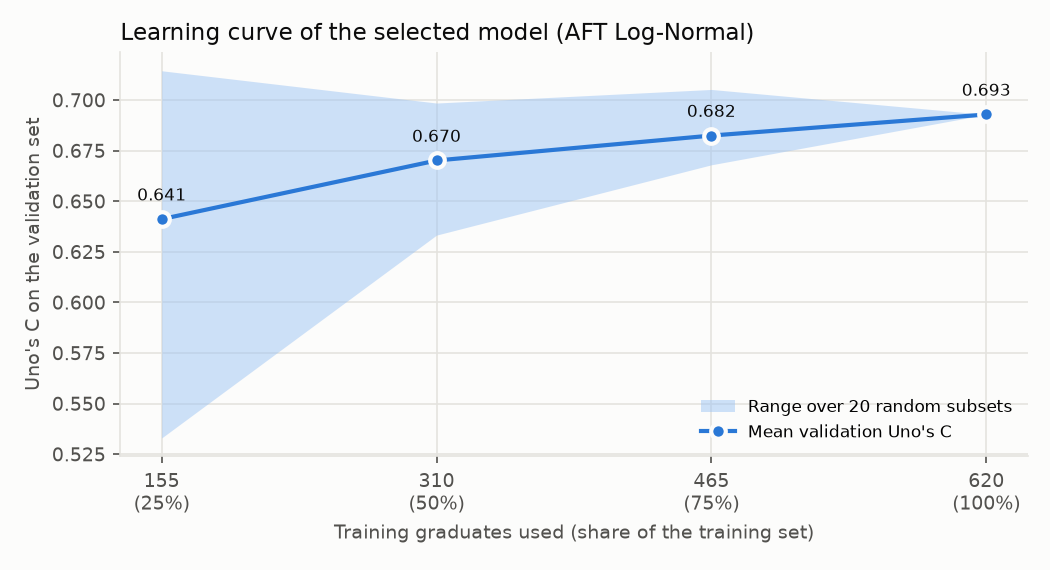

,Share of training set,Training graduates,Random subsets,Uno's C,Lowest,Highest
0,0.25,155,20,0.641,0.533,0.714
1,0.50,310,20,0.670,0.633,0.699
2,0.75,465,20,0.682,0.668,0.705
3,1.00,620,1,0.693,0.693,0.693


In [27]:
# ---- Selected model fitted on 25-100% of the training set (core/learning_curve.py) ------------------------------
lc = learning_curve.run(out_dir=TMP)
show_png(TMP / "figures" / "learning_curve.png", width=760)
show_table(pd.DataFrame(lc["curve"]).round(3))

> **What this shows:** Discrimination rises with more training data but the gains shrink (+0.029, +0.012, +0.010): more respondents answering the same questions would add little.

### 9.2 Simple baselines - how much do the inputs add?

The same model with fewer inputs. If GPA alone did as well, the other inputs would add nothing.

In [28]:
# ---- Baselines (core/baselines.py): paired bootstrap of the validation graduates --------------------------------
bl = baselines.run(out_dir=TMP)
show_table(pd.DataFrame(bl["rows"])[["label", "uno_c", "lo", "hi", "diff_vs_selected", "diff_lo", "diff_hi",
                                  "selected_better_share"]].round(3))

,Model,Uno's C,95% CI low,95% CI high,Difference from selected,Difference CI low,Difference CI high,Selected better in
0,Kaplan-Meier (no model),0.500,NaN,NaN,-0.193,NaN,NaN,NaN
1,GPA only,0.637,0.574,0.696,-0.056,-0.095,-0.021,1.000
2,GPA + internship months,0.675,0.621,0.730,-0.018,-0.050,0.012,0.881
3,Core inputs (8),0.683,0.630,0.739,-0.010,-0.028,0.007,0.854
4,Selected model (extended inputs),0.693,0.636,0.750,0.000,NaN,NaN,NaN


> **What this shows:** GPA alone already reaches 0.637; adding internship gives 0.675, close to the full model (0.693). Most of the ranking comes from these two inputs, consistent with section 8.3.

### 9.3 Time-dependent AUC and the Brier score over time

Supplementary measures (not used for selection). The time-dependent AUC is the survival version of the ROC-AUC; the
Brier score is compared month by month with the Kaplan-Meier baseline, which predicts the same curve for everyone.

,AUC 3 m,AUC 6 m,AUC 12 m,Mean AUC,Uno's C,IBS
Cox PH,0.723,0.749,0.794,0.743,0.667,0.179
Elastic Net Cox,0.730,0.754,0.768,0.743,0.665,0.175
AFT Log-Normal,0.756,0.795,0.808,0.775,0.693,0.171
DeepSurv,0.708,0.782,0.787,0.741,0.679,0.175


Kaplan-Meier baseline IBS on validation: 0.202


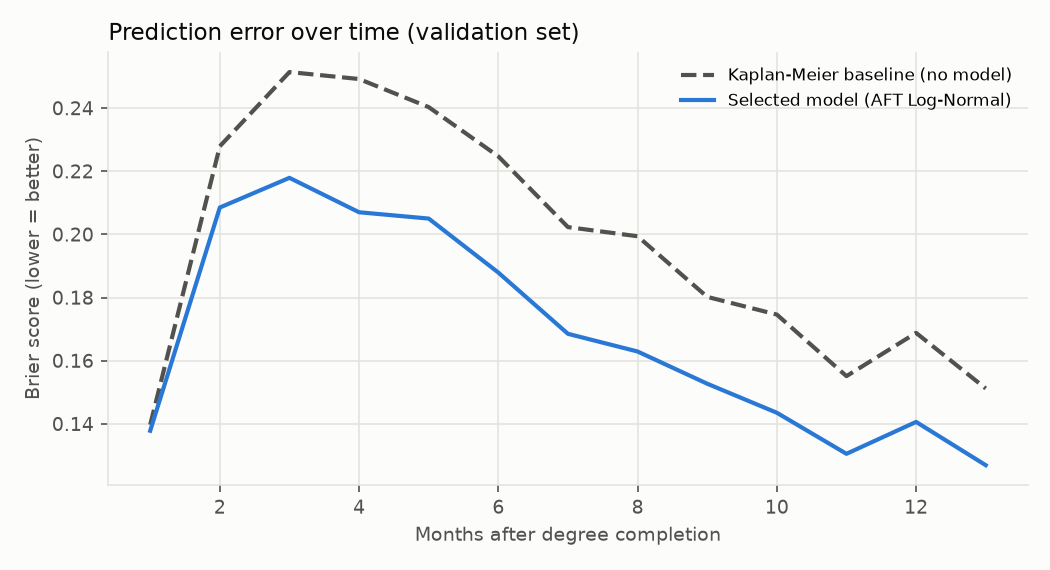

In [29]:
# ---- Time-dependent metrics for every candidate (core/time_dependent_metrics.py) --------------------------------
td = time_dependent_metrics.run(out_dir=TMP)
show_table(pd.DataFrame(td["models"]).set_index("label")[["auc_3m", "auc_6m", "auc_12m", "auc_mean", "uno_c", "ibs"]]
        .round(3))
print(f"Kaplan-Meier baseline IBS on validation: {td['ibs_km']:.3f}")
show_png(TMP / "figures" / "brier_over_time.png", width=760)

> **What this shows:** The selected model has the highest AUC at 3, 6 and 12 months (about 0.76-0.81) and, on validation, a lower Brier score than the no-model baseline at every month. This did not carry over to the test set (section 10): validation is the set the model was chosen on, so its figures are optimistic.

### 9.4 Error analysis - where does the model go wrong?

Predicted median time against the actual time, for validation graduates who found work. Group summaries only.

In [30]:
# ---- Error analysis (core/error_analysis.py); individual cases go to the scratch folder, not shown -------------
ea = error_analysis.run(out_dir=TMP, cases_path=TMP / "cases.csv")
show_table(pd.DataFrame(ea["bands"]).round(2))
print(f"Mean absolute error {ea['mae_events']:.1f} months; predicted medians range "
      f"{ea['predicted_range'][0]:.1f}-{ea['predicted_range'][1]:.1f} months (SD {ea['sd_predicted']:.1f} vs "
      f"{ea['sd_actual']:.1f} actual): the model pulls everyone towards the typical search length")
show_table(pd.DataFrame(ea["worst_vs_rest"]).round(2))

,Actual time to first IT job,N,Mean actual (months),Mean predicted median,Mean error,Mean absolute error
0,at or before completion,18,0.50,3.86,3.36,3.36
1,1-3 months,40,2.28,4.08,1.80,1.89
2,4-6 months,22,4.91,4.64,-0.27,1.43
3,7-12 months,13,8.62,5.56,-3.06,3.06
4,more than 12 months,7,16.29,7.25,-9.04,9.04


Mean absolute error 2.7 months; predicted medians range 1.8-11.2 months (SD 1.8 vs 4.3 actual): the model pulls everyone towards the typical search length


,Input,Worst-predicted tenth,Rest
0,GPA,2.81,3.14
1,Internship (months),3.91,5.47
2,Certifications,0.55,0.90
3,Projects,1.64,2.98
4,Technical skills (1-5),2.63,3.08
5,Found work at or before completion (%),9.09,19.10


> **What this shows:** Predictions are pulled towards the typical 4-5 months: fast hires are predicted too slow and long searches far too fast. The worst-predicted graduates had weaker profiles but searched longer than predicted - what the questionnaire cannot capture (networks, search effort, interviews).

<a id="s10"></a>

## 10. Final result on the locked test set (loaded, not recomputed)

The selected model was evaluated **once** on the 132 test graduates, in `core/evaluate.py`, after it had been chosen.
Those saved results are loaded here; nothing in this notebook fits, tunes or scores on the test set.

,Locked test set
Model,AFT (best by AIC)
Graduates,132
Events,100
Uno's C,0.619 (0.557-0.683)
Harrell's C,0.626
IBS,0.167
Calibration error 3 / 6 / 12 m,0.152 / 0.169 / 0.078


Kaplan-Meier baseline IBS on the test set: 0.164 (model 0.167) - the model ranks graduates but its probabilities are not better


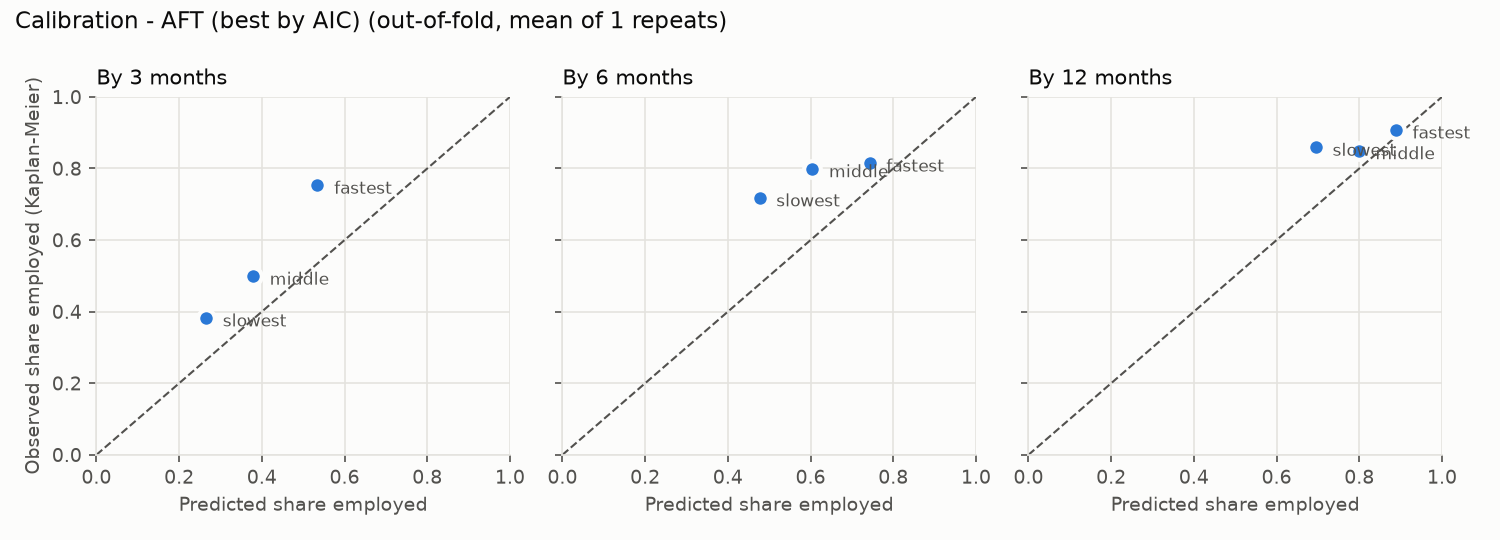

In [31]:
# ---- Load the one test-set evaluation ---------------------------------------------------------------------------
test = json.loads((ART / "test_metrics.json").read_text(encoding="utf-8"))
show_table(pd.DataFrame([{
    "Model": test["model"], "Graduates": test["n"], "Events": test["events"],
    "Uno's C": f"{test['uno_c']:.3f} ({test['uno_c_lo']:.3f}-{test['uno_c_hi']:.3f})",
    "Harrell's C": round(test["harrell_c"], 3), "IBS": round(test["ibs"], 3),
    "Calibration error 3 / 6 / 12 m": f"{test['cal_err_3m']:.3f} / {test['cal_err_6m']:.3f} / {test['cal_err_12m']:.3f}",
}]).T.rename(columns={0: "Locked test set"}))

model_checks = json.loads((ART / "thesis_results.json").read_text(encoding="utf-8"))["model_checks"]
print(f"Kaplan-Meier baseline IBS on the test set: {model_checks['ibs_test_km_baseline']:.3f} "
      f"(model {model_checks['ibs_test_model']:.3f}) - the model ranks graduates but its probabilities are not better")
show_png(FIG / "calibration_test.png")

> **What this shows:** On new graduates the model ranks better than chance (C 0.619, CI 0.557-0.683) but its overall error is no better than the Kaplan-Meier baseline (0.167 vs 0.164) and it under-predicts employment by up to 17 points. The ranking is useful; the probabilities should be read as indicative, which is how the app presents them.

### 10.0 Conditions under which the model is claimed to work (thesis Table 5.4)

The conditions were fixed in advance (thesis Table 3.6). The evidence below is loaded from the saved results; the
verdicts are those reported in the thesis.

In [32]:
# ---- Evidence for each pre-set condition (saved results) ----------------------------------------------------------
checks_saved = json.loads((ART / "thesis_results.json").read_text(encoding="utf-8"))
c, transfer = checks_saved["model_checks"]["uno_c"], checks_saved["institution_transfer"]
fair = {r["level"]: r for r in ev["fairness"]}
conditions = pd.DataFrame([
    ("Better than no model", f"Test C {test['uno_c_lo']:.3f}-{test['uno_c_hi']:.3f} above 0.5; IBS {test['ibs']:.3f} vs "
     f"baseline {checks_saved['model_checks']['ibs_test_km_baseline']:.3f}", "Partly: ranks, but no lower overall error"),
    ("Probabilities are correct", f"Under-prediction of {100 * test['cal_err_12m']:.0f}-{100 * test['cal_err_6m']:.0f} "
     "points at 3, 6 and 12 months", "No"),
    ("Results are stable", f"Validation {c['validation']} vs test {c['test']}; intervals overlap", "Partly"),
    ("Works across institutions", "Fitted without one type, C on that type: " +
     ", ".join(f"{evaluation_figures.GROUP_LABELS.get(t['held_out_type'], t['held_out_type'])} {t['uno_c']}"
               for t in transfer), "Yes"),
    ("Fair across groups", f"Test C: women {fair['female']['uno_c']:.3f}, men {fair['male']['uno_c']:.3f} (overlapping CIs)",
     "Partly"),
    ("Model assumptions hold", f"No Schoenfeld violation (smallest p {min(ev['schoenfeld_p'].values()):.3f}); AFT chosen by AIC",
     "Yes"),
    ("Not overfitted", f"Training C {c['train']} vs test C {c['test']}", "Yes"),
], columns=["Condition", "Evidence", "Met? (as reported)"])
show_table(conditions)

,Condition,Evidence,Met? (as reported)
0,Better than no model,Test C 0.557-0.683 above 0.5; IBS 0.167 vs baseline 0.164,"Partly: ranks, but no lower overall error"
1,Probabilities are correct,"Under-prediction of 8-17 points at 3, 6 and 12 months",No
2,Results are stable,Validation 0.693 vs test 0.619; intervals overlap,Partly
3,Works across institutions,"Fitted without one type, C on that type: State 0.702, Non-state 0.695, Forei...",Yes
4,Fair across groups,"Test C: women 0.724, men 0.574 (overlapping CIs)",Partly
5,Model assumptions hold,No Schoenfeld violation (smallest p 0.110); AFT chosen by AIC,Yes
6,Not overfitted,Training C 0.613 vs test C 0.619,Yes


> **What this shows:** Four conditions are met, two partly, and one (correct probabilities) is not - reported openly rather than tuned away.

### 10.1 Fairness (test set, from the saved fairness report)

Uno's C and calibration at six months by gender and institution type. Gender is never a model input.

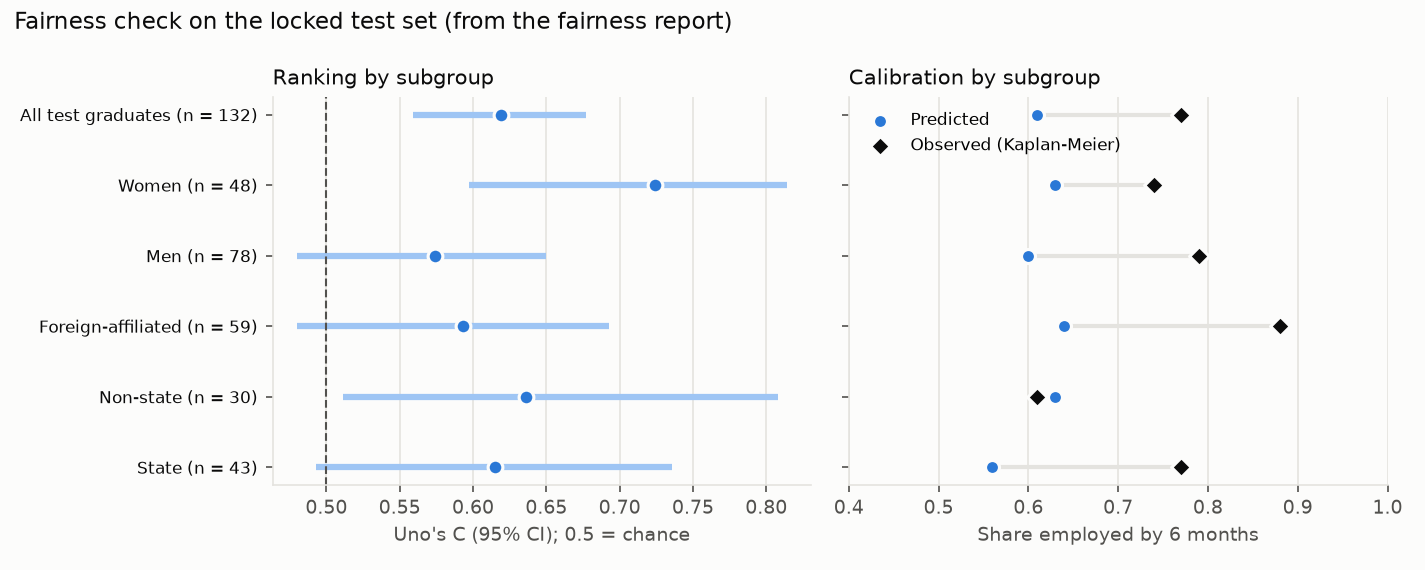

,Group,Level,N,Events,Uno's C,95% CI low,95% CI high,Predicted employed by 6 m,Observed employed by 6 m
0,all,All test graduates,132,100,0.619,0.559,0.677,0.61,0.77
1,gender,Women,48,35,0.724,0.597,0.814,0.63,0.74
2,gender,Men,78,61,0.574,0.480,0.650,0.60,0.79
3,university_type,Foreign-affiliated,59,45,0.593,0.480,0.693,0.64,0.88
4,university_type,Non-state,30,23,0.636,0.511,0.808,0.63,0.61
5,university_type,State,43,32,0.615,0.493,0.736,0.56,0.77


In [33]:
# ---- Fairness chart (drawn from artifacts/fairness_report.md by evaluation_figures.run) --------------------------
show_png(TMP / "figures" / "fairness.png")
show_table(pd.DataFrame(ev["fairness"])[["group", "level", "n", "events", "uno_c", "lo", "hi", "predicted_6m",
                                      "observed_6m"]])

> **What this shows:** The model ranked women (0.724) better than men (0.574), but the intervals overlap, so the gap may be chance. It under-predicted employment in most groups, as it did overall.

<a id="s11"></a>

## 11. Robustness

The selected model's validation Uno's C under alternative data decisions (sensitivity analysis), on later cohorts
when trained on earlier ones (temporal validation), and with each institution type held out of training.

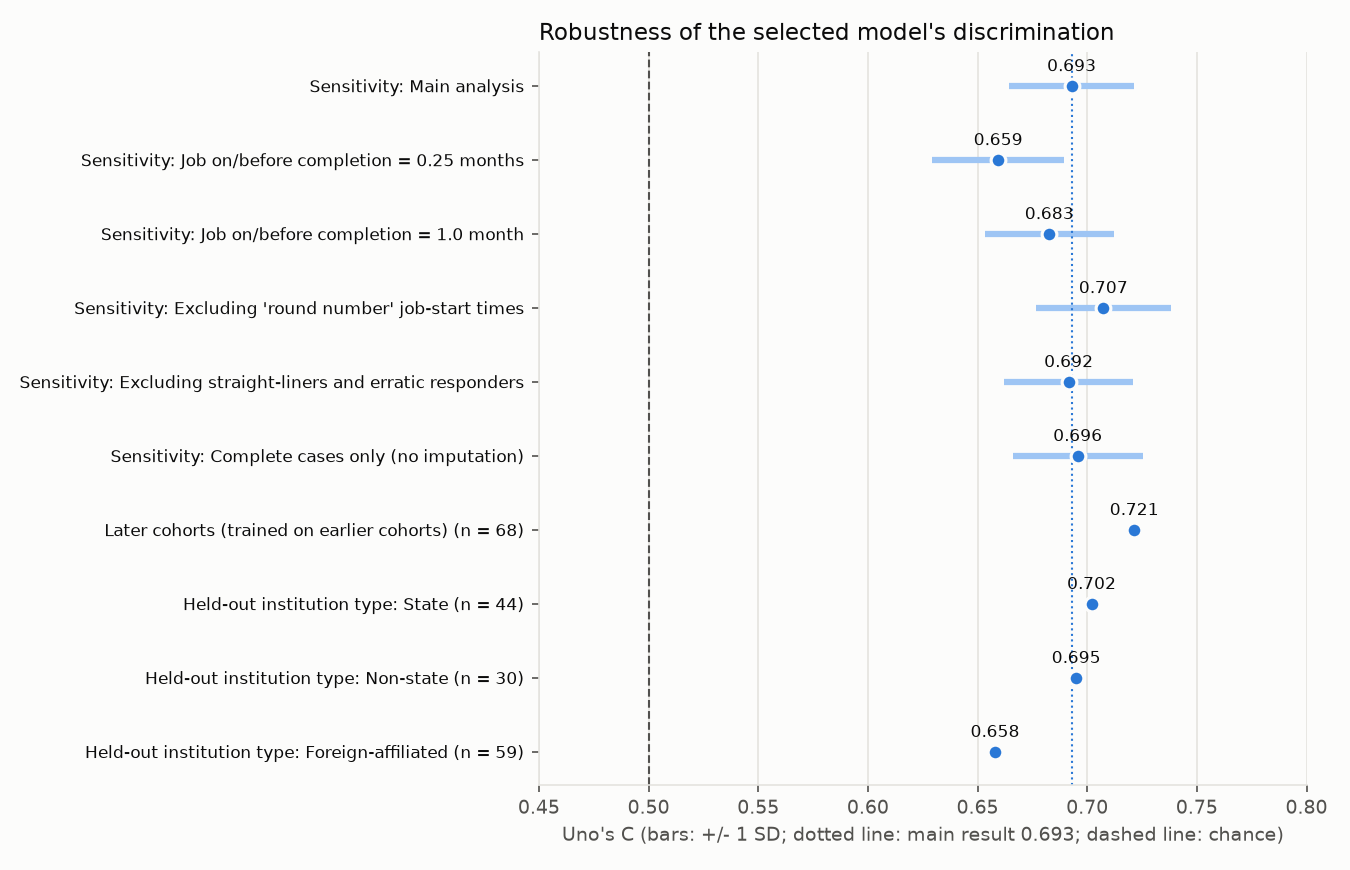

,Model,N,Events,Uno's C,SD,IBS
1,Main analysis,620,467,0.693,0.029,0.171
3,Job on/before completion = 0.25 months,620,467,0.659,0.030,0.177
5,Job on/before completion = 1.0 month,620,467,0.683,0.030,0.175
7,Excluding 'round number' job-start times,502,349,0.707,0.031,0.182
9,Excluding straight-liners and erratic responders,620,467,0.692,0.029,0.173
11,Complete cases only (no imputation),548,409,0.696,0.030,0.166


,Model,Uno's C,IBS,Uno c cv,Max abs cal error
0,Cox PH,0.723,0.117,0.667,0.105
1,Elastic Net Cox,0.705,0.116,0.665,0.108
2,DeepSurv,0.727,0.114,0.679,0.113
3,AFT (best by AIC),0.721,0.115,0.693,0.119


In [34]:
# ---- Robustness chart and the underlying tables (saved reports) -------------------------------------------------
show_png(TMP / "figures" / "robustness.png")
sensitivity = pd.read_csv(ART / "sensitivity.csv")
show_table(sensitivity[sensitivity["model"] == "aft_best"][["label", "n", "events", "uno_c", "uno_c_sd", "ibs"]].round(3))
show_table(pd.read_csv(ART / "temporal_validation.csv").round(3))

> **What this shows:** Across every alternative data decision, later cohorts and each institution type held out, the C-index stayed between 0.658 and 0.721 - within 0.035 of the main result. The ranking does not depend on one choice.

<a id="s12"></a>

## 12. Skill gaps: graduates, employers and job advertisements (RQ2)

Gap = employers' importance rating minus graduates' self-rating (both 1-5), tested with the Mann-Whitney U test and
corrected for 26 tests (Benjamini-Hochberg q). The share of job advertisements naming each skill is shown alongside.

,Skill,Type,Graduates (mean),Employers (mean),Gap,Rank-biserial,q (BH),Share of ads
0,Cloud Computing,Technical,2.323,3.523,1.200,0.660,0.000,0.228
1,Software Testing,Technical,2.724,3.921,1.197,0.694,0.000,0.441
2,DevOps / CI-CD,Technical,1.959,3.075,1.117,0.627,0.000,0.099
3,Docker,Technical,2.091,3.021,0.929,0.530,0.000,0.080
4,Cybersecurity Fundamentals,Technical,2.541,3.448,0.907,0.503,0.000,0.123
5,Problem Solving,Soft,3.658,4.556,0.898,0.563,0.000,0.688
6,Communication Skills,Soft,3.733,4.569,0.836,0.498,0.000,0.549
7,Git / GitHub,Technical,3.312,4.013,0.700,0.427,0.000,0.262
8,REST APIs,Technical,3.133,3.833,0.700,0.418,0.000,0.330
9,Linux / Command Line,Technical,2.634,3.318,0.684,0.416,0.000,0.090


Employer importance vs share of ads (Spearman): rho = 0.386, p = 0.052


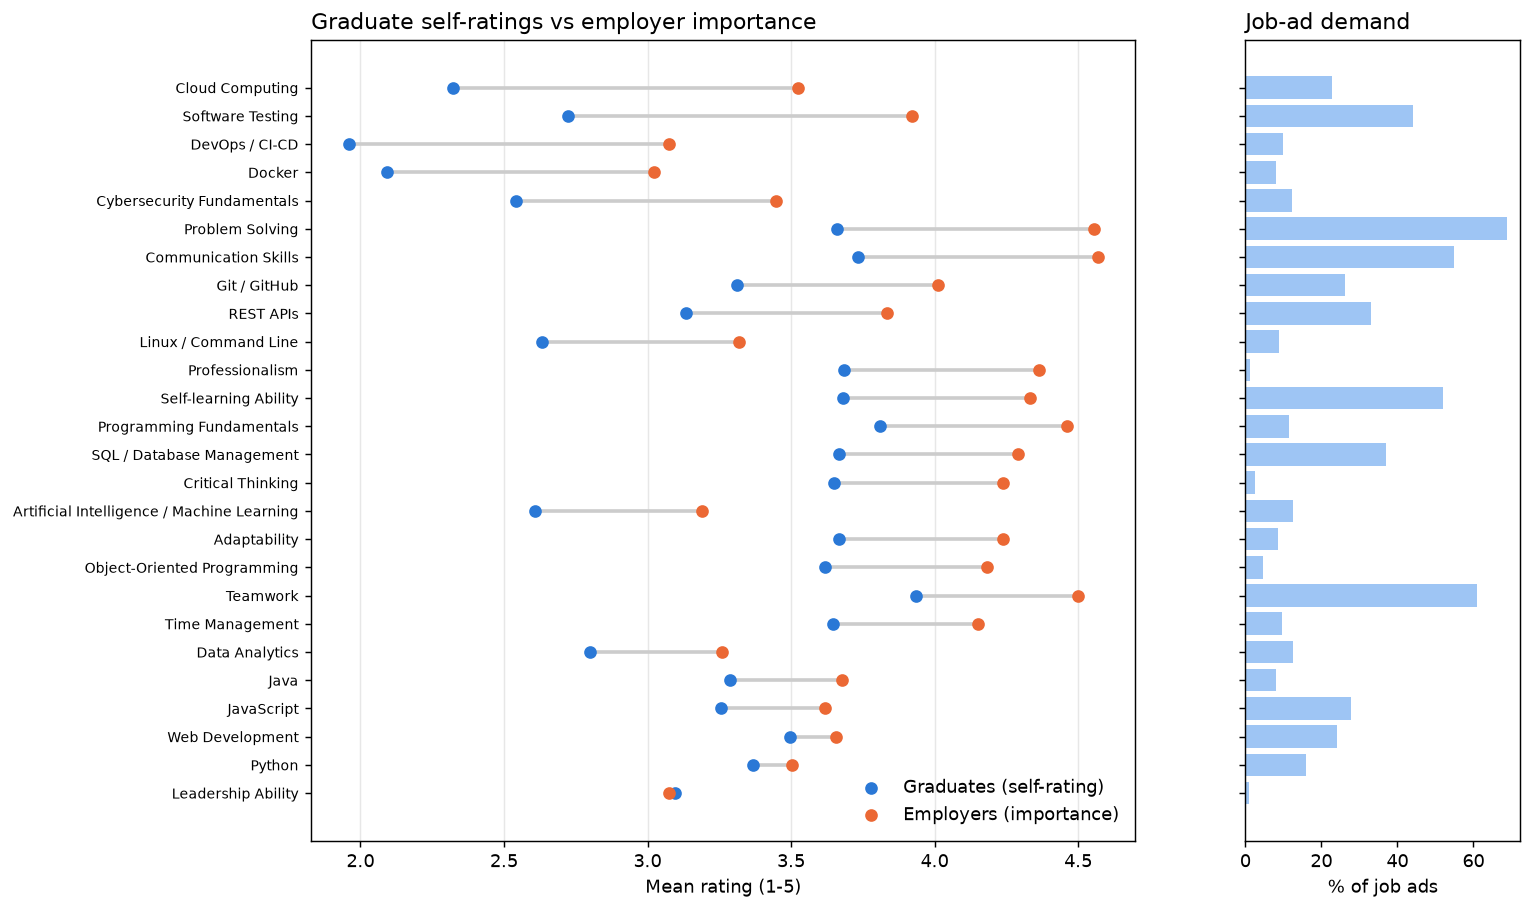

In [35]:
# ---- Per-skill alignment (core/thesis_results.py) ---------------------------------------------------------------
align, align_summary = thesis_results.alignment()
show_table(align[["skill", "kind", "graduate_mean", "employer_mean", "gap", "rank_biserial", "q", "ad_share"]].round(3))
print(f"Employer importance vs share of ads (Spearman): rho = {align_summary['spearman_rho']}, "
      f"p = {align_summary['p']:.3f}")

# ---- Dumbbell chart: graduates vs employers per skill, with the share of ads -------------------------------------
a = align.sort_values("gap")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8), sharey=True, gridspec_kw={"width_ratios": [3, 1]})
y = np.arange(len(a))
ax1.hlines(y, a["graduate_mean"], a["employer_mean"], color="#cccccc", linewidth=2)
ax1.scatter(a["graduate_mean"], y, color="#2a78d6", label="Graduates (self-rating)", zorder=3)
ax1.scatter(a["employer_mean"], y, color="#eb6834", label="Employers (importance)", zorder=3)
ax1.set_yticks(y, a["skill"], fontsize=8); ax1.set_xlabel("Mean rating (1-5)"); ax1.legend(frameon=False, loc="lower right")
ax1.set_title("Graduate self-ratings vs employer importance", loc="left"); ax1.grid(axis="x", alpha=0.3)
ax2.barh(y, 100 * a["ad_share"], color="#9ec5f4"); ax2.set_xlabel("% of job ads"); ax2.set_title("Job-ad demand", loc="left")
show_fig(fig)

> **What this shows:** Graduates rated themselves below employers' expectations on 25 of 26 skills, most in cloud computing, software testing and DevOps. Advertisements asked most for problem solving, teamwork and communication, and employers' importance ratings only loosely matched what they advertised (rho 0.39).

<a id="s13"></a>

## 13. Usability and the LLM benchmark (RQ4)

### 13.1 System Usability Scale (12 participants)

,Usability
Participants,12
Mean SUS,76.25
95% CI,69.53-82.97
Benchmark,68.0
t-test p (one-sided),0.0103
Approx. percentile,75


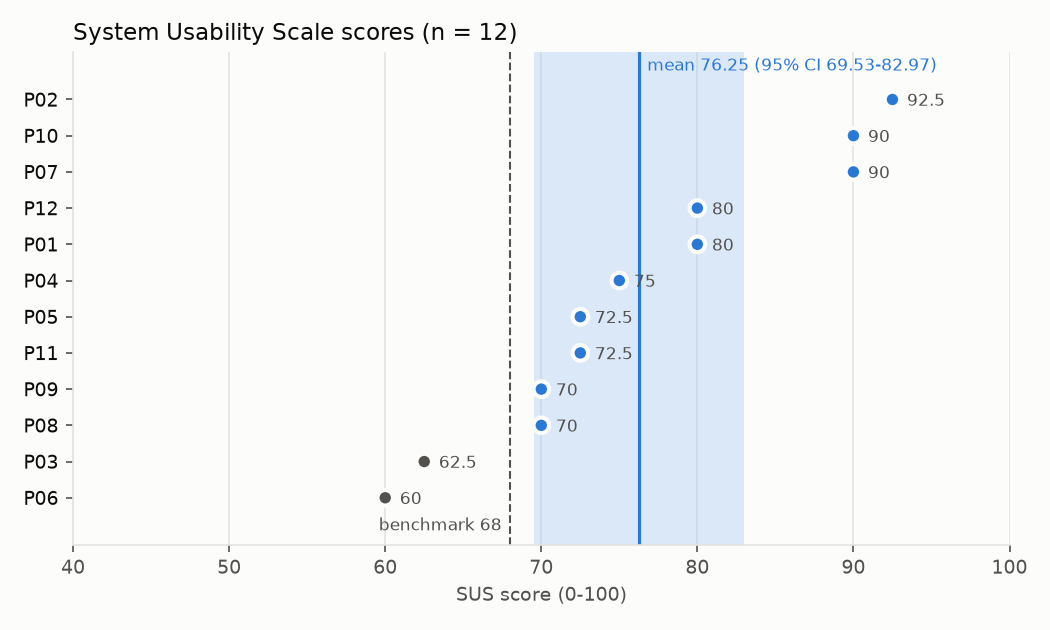

,Item,Statement,Tone,Mean answer,SD,Mean contribution
0,SUS1,I think that I would like to use this system frequently.,positive,4.17,0.39,3.17
1,SUS2,I found the system unnecessarily complex.,negative,1.92,0.67,3.08
2,SUS3,I thought the system was easy to use.,positive,4.08,0.67,3.08
3,SUS4,I think that I would need the support of a technical person to be able to us...,negative,1.67,0.49,3.33
4,SUS5,I found the various functions in this system were well integrated.,positive,3.75,0.62,2.75
5,SUS6,I thought there was too much inconsistency in this system.,negative,2.00,0.60,3.00
6,SUS7,I would imagine that most people would learn to use this system very quickly.,positive,4.25,0.62,3.25
7,SUS8,I found the system very cumbersome to use.,negative,2.00,0.43,3.00
8,SUS9,I felt very confident using the system.,positive,4.00,0.60,3.00
9,SUS10,I needed to learn a lot of things before I could get going with this system.,negative,2.17,0.72,2.83


In [36]:
# ---- SUS results, recomputed live from the form responses (core/sus_study.py) -----------------------------------
if not sus_study.SOURCE.exists():
    print("No usability responses here (synthetic mode): this section needs the real SUS study.")
else:
    sus_result = sus_study.run(out_dir=TMP)          # scores, tests and chart written to the scratch folder
    sus = sus_result["summary"]
    show_table(pd.DataFrame([{"Participants": sus["n"], "Mean SUS": sus["mean"],
                           "95% CI": f"{sus['ci_low']}-{sus['ci_high']}", "Benchmark": sus["benchmark"],
                           "t-test p (one-sided)": round(sus["p_one_sided"], 4), "Approx. percentile": sus["percentile_approx"]}]).T
            .rename(columns={0: "Usability"}))
    show_png(TMP / "figures" / "sus_scores.png", width=760)

    # ---- Each SUS statement (thesis Table G.1): mean answer and its contribution to the score ---------------------
    items = pd.DataFrame(sus_result["items"])
    show_table(items[["item", "text", "tone", "mean_answer", "sd", "mean_contribution"]])

> **What this shows:** Usability was above the benchmark: 76.25 against 68 (one-sided p = 0.010), about the 75th percentile. The participants were the researcher's peers, which may favour positive ratings.

### 13.2 The model against a general-purpose LLM

The same 132 test profiles were given to ChatGPT; both are scored with Uno's C. (Saved result of
`python -m benchmark.score`.)

In [37]:
# ---- LLM benchmark (saved result) -------------------------------------------------------------------------------
if not (ART / "llm_benchmark.json").exists():
    print("No LLM answers here (synthetic mode): this section needs the recorded ChatGPT responses.")
else:
    llm = json.loads((ART / "llm_benchmark.json").read_text(encoding="utf-8"))["comparisons"][0]
    show_table(pd.DataFrame([{"LLM": llm["llm"], "Profiles": llm["profiles"], "LLM Uno's C": llm["uno_c"],
                           "Model Uno's C": llm["model_uno_c"],
                           "Difference (95% CI)": f"{llm['diff'][0]:+.3f} ({llm['diff'][1]:+.3f} to {llm['diff'][2]:+.3f})"}]))

    # ---- Calibration and consistency across runs (thesis Table H.1; saved report) --------------------------------
    show_report("llm_benchmark.md", start="## Per run", stop="## Notes", max_lines=40)

,Llm,Profiles,Llm uno's c,Model uno's c,Difference (95% ci)
0,ChatGPT GPT-5.6,132,0.539,0.619,+0.081 (+0.030 to +0.131)


## Per run

| LLM | Run | Profiles | Uno's C | Harrell's C | Cal. error 6m |
|---|---|---|---|---|---|
| ChatGPT GPT-5.6 | 1 | 132 | 0.531 | 0.533 | 0.246 |
| ChatGPT GPT-5.6 | 2 | 30 | 0.591 | 0.598 | 0.217 |
| ChatGPT GPT-5.6 | 3 | 30 | 0.500 | 0.506 | 0.275 |

## Consistency across runs

| LLM | Runs | Profiles in all runs | Mean within-profile SD (months) | % identical answers | Mean Spearman between runs |
|---|---|---|---|---|---|
| ChatGPT GPT-5.6 | 3 | 30 | 1.37 | 3.3 | 0.418 |

### Calibration at 6 months - ChatGPT GPT-5.6 (mean of runs)

| Tertile | n | Predicted employed by 6m | Observed (KM) |
|---|---|---|---|
| slowest | 44 | 0.64 | 0.84 |
| middle | 44 | 1.00 | 0.71 |
| fastest | 44 | 1.00 | 0.80 |


> **What this shows:** On the same 132 test graduates the model ranked better than ChatGPT (0.619 vs 0.539); the difference's interval excludes 0. ChatGPT's answers also changed between runs.

### 13.3 Job-advertisement coding agreement (thesis Table I.1)

The job advertisements were coded to the 26-skill vocabulary by fixed keyword rules; 40 randomly sampled
advertisements were also hand-coded blind to the keyword result (`python -m core.coding_agreement`).

In [38]:
# ---- Cohen's kappa between hand coding and the keyword rules (saved report) --------------------------------------
show_report("coding_agreement.md", start="36 randomly", max_lines=40)

36 randomly sampled keyword-coded ads, hand-coded blind to the keyword result; 4 left uncoded by the coder, for example because the advert could no longer be opened (R080, R239, R138, R246).

- Pooled Cohen's kappa: **0.83** (conventionally, 0.61-0.80 is substantial and above 0.80 almost perfect agreement; the pre-set target was at least 0.60)
- Keyword precision 0.96, recall 0.80

| Skill | Hand | Keyword | Agreement | Kappa |
|---|---|---|---|---|
| Programming Fundamentals | 14 | 5 | 75% | 0.40 |
| Object-Oriented Programming | 0 | 0 | 100% | - |
| Java | 5 | 5 | 100% | 1.00 |
| Python | 5 | 5 | 100% | 1.00 |
| JavaScript | 13 | 13 | 100% | 1.00 |
| SQL / Database Management | 14 | 14 | 100% | 1.00 |
| Git / GitHub | 16 | 16 | 100% | 1.00 |
| Software Testing | 18 | 17 | 86% | 0.72 |
| REST APIs | 15 | 15 | 100% | 1.00 |
| Web Development | 19 | 9 | 72% | 0.46 |
| Cloud Computing | 6 | 7 | 97% | 0.91 |
| Linux / Command Line | 1 | 1 | 100% | 1.00 |
| Docker | 3 | 3 | 100% | 1.00 |
| DevOps / CI-CD | 3 | 3 | 100% | 1.00 |
| Cybersecurity Fundamentals | 3 | 3 | 94% | 0.64 |
| Data Analytics | 4 | 5 | 97% | 0.87 |
| Artificial Intelligence / Machine Learning | 3 | 5 | 94% | 0.72 |
| Communication Skills | 24 | 24 | 100% | 1.00 |
| Teamwork | 29 | 26 | 92% | 0.77 |
| Problem Solving | 29 | 27 | 89% | 0.68 |
| Critical Thinking | 14 | 1 | 64% | 0.09 |
| Adaptability | 8 | 3 | 86% | 0.48 |
| Time Management | 5 | 6 | 92% | 0.68 |
| Professionalism | 3 | 0 | 92% | 0.00 |
| Self-learning Ability | 21 | 18 | 92% | 0.83 |
| Leadership Ability | 0 | 0 | 100% | - |

> **What this shows:** Agreement between the keyword rules and hand coding is almost perfect overall (kappa 0.83) but weak for broadly worded skills such as critical thinking, which the rules under-count.

<a id="s14"></a>

## 14. Secondary analyses (saved reports)

These analyses support the main results and are reported in the thesis and `docs/secondary_analyses.md`. Each was run
once by its own script; its saved report is shown here rather than re-run (some take several minutes).

### 14.1 Feature-set comparison (pre-registered rule)

In [39]:
# ---- Core vs extended vs transformed inputs (core/feature_sets.py) -----------------------------------------------
show_report("feature_set_comparison.md", start="## Pre-registered decision rule", stop="## Each extended")

## Pre-registered decision rule

A set replaces **core** only if, for Cox PH, the improvement in validation Uno's C is at least 0.01 **and** it is better in at least 70% of bootstrap resamples; and either its EPV is at least 10 or Elastic Net Cox meets the same criteria. If more than one set passes, the one with the larger improvement is recommended. Combinations of sets are not tested.

## Results (paired, validation set)

| Set | Model | Uno's C core | Uno's C set | Difference (bootstrap SD) | Set better in | IBS core | IBS set |
|---|---|---|---|---|---|---|---|
| extended | Cox PH | 0.664 | 0.667 | +0.003 (0.009) | 66% of 1000 resamples | 0.176 | 0.179 |
| extended | Elastic Net Cox | 0.663 | 0.665 | +0.003 (0.009) | 64% of 1000 resamples | 0.177 | 0.175 |
| transformed | Cox PH | 0.664 | 0.675 | +0.011 (0.008) | 91% of 1000 resamples | 0.176 | 0.174 |
| transformed | Elastic Net Cox | 0.663 | 0.674 | +0.011 (0.008) | 90% of 1000 resamples | 0.177 | 0.175 |

Sets meeting the rule: **transformed**.

**Recommendation: TRANSFORMED.** Currently in use (`schema.FEATURE_SET`): **extended**. The set in use differs from the recommendation - review and update `FEATURE_SET` in core/schema.py, then re-run `python -m core.run_all`.


> **What this shows:** Only the log-transformed set met the pre-registered rule (+0.011, better in 91% of resamples); the extended set used in the app added +0.003 - a deviation reported in the thesis.

### 14.2 Other model families: boosting, forest, other neural networks, ensemble (exploratory)

In [40]:
# ---- Accuracy experiments (core/accuracy_experiments.py) - report only, not candidates --------------------------
show_report("accuracy_experiments.md", start="| Method")

| Method | Validation Uno's C (± SD) | Change vs Cox PH | Better in (bootstrap) |
|---|---|---|---|
| Cox PH (core features) | 0.668 ± 0.032 | - | - |
| Cox PH + non-linear & interaction terms | 0.666 ± 0.031 | -0.001 ± 0.012 | 44% |
| Gradient-boosted Cox | 0.687 ± 0.028 | +0.019 ± 0.019 | 85% |
| Random survival forest | 0.677 ± 0.030 | +0.010 ± 0.014 | 74% |
| DeepSurv (neural net) | 0.674 ± 0.031 | +0.006 ± 0.020 | 60% |
| DeepHit (neural net) | 0.590 ± 0.033 | -0.077 ± 0.031 | 1% |
| Cox-Time (neural net) | 0.674 ± 0.033 | +0.006 ± 0.018 | 62% |
| N-MTLR (neural net) | 0.666 ± 0.031 | -0.001 ± 0.022 | 49% |
| Ensemble (Cox + GBM + RSF) | 0.683 ± 0.030 | +0.015 ± 0.011 | 90% |

> **What this shows:** No other model family - boosting, random forest, other neural networks or an ensemble - beat the selected AFT model (0.693); the best was gradient boosting at 0.687.

### 14.3 Clustering by institution

In [41]:
# ---- Cluster-robust and institution-stratified Cox (core/clustering.py) -----------------------------------------
show_report("institution_clustering.md", start="## Standard errors", max_lines=30)

## Standard errors with and without clustering by institution

HR > 1: associated with finding work sooner (numeric features per one SD).

| Feature | HR | 95% CI (usual) | 95% CI (cluster-robust) | SE ratio | Conservative 95% CI | Stratified by institution |
|---|---|---|---|---|---|---|
| GPA | 1.24 | 1.10-1.40 | 1.12-1.37 | 0.82 | 1.10-1.40 | 1.29 (1.13-1.47) |
| internship experience | 1.12 | 1.03-1.23 | 1.06-1.19 | 0.62 | 1.03-1.23 | 1.15 (1.04-1.27) |
| professional certifications | 1.09 | 1.00-1.19 | 1.02-1.17 | 0.77 | 1.00-1.19 | 1.05 (0.96-1.16) |
| personal / academic projects | 1.07 | 0.95-1.20 | 0.98-1.17 | 0.74 | 0.95-1.20 | 1.03 (0.92-1.17) |
| technical skill ratings | 1.13 | 0.98-1.31 | 1.05-1.22 | 0.52 | 0.98-1.31 | 1.11 (0.96-1.30) |
| soft skill ratings | 0.98 | 0.87-1.12 | 0.92-1.06 | 0.57 | 0.87-1.12 | 0.99 (0.87-1.12) |
| a portfolio (GitHub / website) | 1.02 | 0.92-1.13 | 0.91-1.15 | 1.13 | 0.91-1.15 | 1.00 (0.90-1.11) |
| early preparation for IT jobs | 1.01 | 0.92-1.11 | 0.91-1.11 | 1.07 | 0.91-1.11 | 1.00 (0.91-1.11) |
| self-learning during the degree | 1.01 | 0.90-1.13 | 0.92-1.10 | 0.77 | 0.90-1.13 | 0.99 (0.88-1.11) |
| hackathons and competitions | 1.01 | 0.91-1.11 | 0.92-1.11 | 0.93 | 0.91-1.11 | 1.03 (0.93-1.15) |
| open-source contribution | 0.93 | 0.85-1.03 | 0.83-1.06 | 1.26 | 0.83-1.06 | 0.92 (0.83-1.02) |
| familiarity with software development practices | 0.94 | 0.84-1.06 | 0.88-1.01 | 0.58 | 0.84-1.06 | 0.95 (0.85-1.08) |
| degree programme: IT / Information Systems | 1.12 | 0.91-1.38 | 0.99-1.27 | 0.60 | 0.91-1.38 | 1.13 (0.91-1.41) |
| degree programme: specialised (Cyber Security, Data Science, AI/ML or other) | 1.06 | 0.83-1.35 | 0.89-1.26 | 0.71 | 0.83-1.35 | 1.06 (0.83-1.36) |
| type of institution: non-state institutes | 1.14 | 0.88-1.47 | 0.92-1.41 | 0.84 | 0.88-1.47 | - |
| type of institution: foreign-affiliated institutes | 1.03 | 0.83-1.27 | 0.83-1.26 | 0.97 | 0.83-1.27 | - |

Median SE ratio 0.77 (largest 1.26). A ratio above 1 means ignoring institutions understates uncertainty. A ratio below 1 is common with few clusters, because the sandwich estimator is biased downwards; it is NOT evidence of extra precision. The conservative CI therefore uses the larger of the two standard errors. 0 feature(s) change whether their conservative CI includes 1 (marked *).

Names that match no entry in the university lookup are kept as their own institution; add them to the lookup (`institution` column) to merge them.

The stratified model lets each institution have its own baseline time to employment; if the other hazard ratios stay similar, the associations are not explained by which institution graduates attended. Type of institution cannot be estimated in this model (it is constant within an institution).

> **What this shows:** Allowing for graduates from the same institution changed no conclusion; with only 23 institutions the robust standard errors are themselves imprecise.

### 14.4 Simulation study (synthetic data by design)

In [42]:
# ---- Does the analysis recover effects known to exist? (core/simulation_study.py) -------------------------------
show_report("simulation_study.md", start="## Power", stop="## Bias", max_lines=30)

## Power: share of surveys where the effect is detected (p < 0.05, right direction)

| Predictor | True log-HR | n=150 | n=300 | n=600 | n=1200 |
|---|---|---|---|---|---|
| GPA | +0.40 | 64% | 86% | 99% | 100% |
| Internship months | +0.05 | 22% | 42% | 62% | 90% |
| Certifications | +0.20 | 24% | 38% | 57% | 81% |
| Projects | +0.07 | 32% | 52% | 84% | 94% |
| Technical skills (self-rated) | +0.50 | 40% | 66% | 91% | 100% |
| Soft skills (self-rated) | +0.30 | 9% | 9% | 12% | 18% |
| Degree: IT/IS vs computing | -0.20 | 12% | 10% | 20% | 38% |
| Degree: specialised vs computing | +0.10 | 8% | 6% | 7% | 13% |

## False positives for predictors with NO true effect (expected about 5%)

| Predictor | n=150 | n=300 | n=600 | n=1200 |
|---|---|---|---|---|
| University: non-state vs state | 10% | 8% | 4% | 2% |
| University: foreign-affiliated vs state | 10% | 5% | 8% | 4% |


> **What this shows:** On synthetic data with known effects, the pipeline recovers strong effects such as GPA reliably at this sample size, but small effects (soft skills, degree group) are often missed - so 'no clear association' does not prove 'no effect'.

### 14.5 Job-market study (324 real advertisements)

In [43]:
# ---- Headline results of the job-advertisement study (core/market_study.py) -------------------------------------
show_report("job_market_study.md", max_lines=40)

# Job-market study (real job ads)


**324 real entry-level IT job ads** from **211 companies**, posted 2026-07-12 to 2026-10-11. Sources: other 274, topjobs 42, linkedin 8.

## Skill demand (share of ads, Wilson 95% CI)

| Skill | Type | Ads | % | 95% CI |
|---|---|---|---|---|
| Problem Solving | soft | 223 | 69% | 64-74% |
| Teamwork | soft | 197 | 61% | 55-66% |
| Communication Skills | soft | 178 | 55% | 49-60% |
| Self-learning Ability | soft | 168 | 52% | 46-57% |
| Software Testing | technical | 143 | 44% | 39-50% |
| SQL / Database Management | technical | 120 | 37% | 32-42% |
| REST APIs | technical | 107 | 33% | 28-38% |
| JavaScript | technical | 90 | 28% | 23-33% |
| Git / GitHub | technical | 85 | 26% | 22-31% |
| Web Development | technical | 78 | 24% | 20-29% |
| Cloud Computing | technical | 74 | 23% | 19-28% |
| Python | technical | 52 | 16% | 12-20% |
| Data Analytics | technical | 41 | 13% | 9-17% |
| Artificial Intelligence / Machine Learning | technical | 41 | 13% | 9-17% |
| Cybersecurity Fundamentals | technical | 40 | 12% | 9-16% |
| Programming Fundamentals | technical | 37 | 11% | 8-15% |
| DevOps / CI-CD | technical | 32 | 10% | 7-14% |
| Time Management | soft | 31 | 10% | 7-13% |
| Linux / Command Line | technical | 29 | 9% | 6-13% |
| Adaptability | soft | 28 | 9% | 6-12% |
| Java | technical | 26 | 8% | 6-11% |
| Docker | technical | 26 | 8% | 6-11% |
| Object-Oriented Programming | technical | 15 | 5% | 3-7% |
| Critical Thinking | soft | 8 | 2% | 1-5% |
| Professionalism | soft | 4 | 1% | 0-3% |
| Leadership Ability | soft | 3 | 1% | 0-3% |

## Technical vs soft skills

- An ad names on average **3.2 technical** and **2.6 soft** skills.
- 89% of ads ask for at least one soft skill; 88% for at least one technical skill; 12% ask only for soft skills.

> **What this shows:** Problem solving, teamwork and communication top the 324 advertisements; among technical skills, testing, SQL and REST APIs are asked for more than cloud or AI.

### 14.6 Questionnaire study (items that are not model inputs)

In [44]:
# ---- Headline results of the questionnaire study (core/survey_study.py) -----------------------------------------
show_report("questionnaire_study.md", max_lines=40)

# Questionnaire study


Graduates: 885 (+ 230 final-year). Employers: 239.

## 1. Repeated questions

Each item that asks about a model question again is correlated with it (Spearman). |rho| >= 0.5: the items measure the same thing, so one can be dropped; 0.3-0.5: they partly overlap; below 0.3: they measure something different.

| Repeat item | Model question | rho (95% CI) | n | Verdict |
|---|---|---|---|---|
| Q25 Java ticked | Q18 Java rating | 0.648 (0.612 to 0.681) | 1115 | repeats the model question - keep one |
| Q25 Python ticked | Q18 Python rating | 0.61 (0.571 to 0.645) | 1115 | repeats the model question - keep one |
| Q25 JavaScript ticked | Q18 JavaScript rating | 0.749 (0.722 to 0.773) | 1115 | repeats the model question - keep one |
| Q27 Unfamiliar-problem confidence | Q19 Problem Solving | 0.293 (0.237 to 0.347) | 1066 | measures something different |
| Q32 Explaining to non-technical people | Q19 Communication | 0.76 (0.733 to 0.784) | 1074 | repeats the model question - keep one |
| Q33 Team confidence | Q19 Teamwork | 0.691 (0.658 to 0.721) | 1070 | repeats the model question - keep one |
| Q34 Group projects (yes) | Q33 Team confidence | 0.042 (-0.018 to 0.102) | 1070 | measures something different |
| Q28 Version control used | Q18 Git / GitHub rating | 0.261 (0.204 to 0.316) | 1081 | measures something different |
| Q28 Testing practices used | Q18 Software Testing rating | 0.189 (0.131 to 0.246) | 1081 | measures something different |
| Q28 CI/CD used | Q18 DevOps / CI-CD rating | 0.198 (0.14 to 0.254) | 1081 | measures something different |
| Q28 Number of practices used | Q29 SDLC familiarity | 0.175 (0.116 to 0.232) | 1081 | measures something different |

**Logic checks** (answers that contradict each other):

| Check | Contradictions | % (95% CI) |
|---|---|---|
| Q11 internship = yes but Q12 = 0 months | 0 / 1115 | 0.0 (0.0-0.3) |
| Q14 no portfolio but Q15 updates it occasionally / frequently | 1 / 1059 | 0.1 (0.0-0.5) |
| Q38 no LinkedIn profile but Q36 searched on LinkedIn | 1 / 915 | 0.1 (0.0-0.6) |
| Q34 no group projects but Q34a gives a number | 0 / 1115 | 0.0 (0.0-0.3) |

## 2. Graduates vs employers

| Question | Graduates mean | Employers mean | Rank-biserial | p | q (BH) |
|---|---|---|---|---|---|
| Graduates are prepared for industry (Q42 vs E14) | 2.96 | 2.9 | -0.04 | 0.322 | 0.429 |
| Importance of explanations from an AI system (Q44 vs E17) | 4.25 | 4.45 | 0.137 | <0.001 | <0.001 |
| Would use / find useful an AI employability system (Q46 vs E16) | 3.83 | 3.83 | 0.007 | 0.868 | 0.868 |
| English: graduates' proficiency vs employers' importance (Q7b vs E9a) | 3.38 | 4.31 | 0.55 | <0.001 | <0.001 |

> **What this shows:** Repeated questions mostly agree with the model questions they repeat; graduates and employers differ on what matters most for employability (section 12).

### 14.7 Automated tests

The project's test suite (thesis Appendix F) is collected here, not run, to show its size; run `pytest` to execute it.
API response times (thesis Table F.3) were measured against the running service and are not repeated here.

In [45]:
# ---- Count the automated tests without running them (always in the real project folder) -----------------------
collected = subprocess.run([sys.executable, "-m", "pytest", "--collect-only", "-q", "--color=no"], capture_output=True,
                           text=True, cwd=PROJECT).stdout.strip().splitlines()
print(collected[-1])                                              # e.g. "295 tests collected in ..."
per_file = pd.Series([l.split("::")[0] for l in collected if "::" in l]).value_counts().sort_index()
show_table(per_file.rename("tests").to_frame())

294 tests collected in 3.48s


,Tests
tests/test_api.py,45
tests/test_benchmark.py,28
tests/test_chat.py,21
tests/test_clean.py,13
tests/test_conditional_actionable.py,9
tests/test_explain_whatif.py,21
tests/test_fairness.py,5
tests/test_feature_sets.py,6
tests/test_guidance.py,7
tests/test_market_peers.py,9


<a id="s15"></a>

## 15. Summary and consistency check

The key numbers computed live in this notebook are compared with the results reported in the thesis (saved in
`artifacts/`). Every row should match.

In [46]:
# ---- Compare live results with the saved, reported ones ---------------------------------------------------------
selection = json.loads((ART / "selection.json").read_text(encoding="utf-8"))
sel_row = comparison_table.set_index("model").loc[selected]
gpa_ratio = ratios.loc["gpa", "time ratio"] if "gpa" in ratios.index else np.nan
intern_ratio = ratios.loc["internship_months", "time ratio"] if "internship_months" in ratios.index else np.nan
saved_ratios = json.loads((ART / "thesis_results.json").read_text(encoding="utf-8"))["time_ratios"]

checks = [
    ("Modelling graduates", len(grads), info["modelling_n"]),
    ("Kaplan-Meier median (months)", km["median_months"], 4.0),
    ("Selected model", evaluate.LABELS[selected], "AFT (best by AIC)"),
    ("Validation Uno's C, selected model", round(sel_row["uno_c_mean"], 3), selection["uno_c_validation"]),
    ("Time ratio: GPA", round(gpa_ratio, 2), round(saved_ratios["gpa"]["time_ratio"], 2)),
    ("Time ratio: internship months", round(intern_ratio, 2), round(saved_ratios["internship_months"]["time_ratio"], 2)),
    ("Cronbach's alpha, technical", round(alpha["Technical (17 items)"], 3), 0.925),
    ("Cronbach's alpha, soft", round(alpha["Soft (9 items)"], 3), 0.902),
    ("Learning curve at 100% vs AFT log-normal validation C", round(lc["curve"][-1]["uno_c_mean"], 3),
     round(comparison_table.set_index("model").loc["aft_lognormal", "uno_c_mean"], 3)),
    ("Test Uno's C (loaded, evaluated once)", round(test["uno_c"], 3), selection["uno_c"]),
]
if USE_SYNTHETIC:      # the fixed thesis values describe the real data; keep only comparisons with saved results
    checks = [c for c in checks if c[0] not in ("Kaplan-Meier median (months)", "Selected model",
                                                "Cronbach's alpha, technical", "Cronbach's alpha, soft")]
check = pd.DataFrame(checks, columns=["Result", "This notebook", "Reported"])
check["Match"] = [str(a) == str(b) for a, b in zip(check["This notebook"], check["Reported"])]
show_table(check)
print("All key results match the reported ones." if check["Match"].all() else "Some results differ - see above.")

,Result,This notebook,Reported,Match
0,Modelling graduates,885,885,True
1,Kaplan-Meier median (months),4.0,4.0,True
2,Selected model,AFT (best by AIC),AFT (best by AIC),True
3,"Validation Uno's C, selected model",0.693,0.693,True
4,Time ratio: GPA,0.8,0.8,True
5,Time ratio: internship months,0.84,0.84,True
6,"Cronbach's alpha, technical",0.925,0.925,True
7,"Cronbach's alpha, soft",0.902,0.902,True
8,Learning curve at 100% vs AFT log-normal validation C,0.693,0.693,True
9,"Test Uno's C (loaded, evaluated once)",0.619,0.619,True


All key results match the reported ones.


### What the results say

* **RQ1 - factors.** Most graduates found IT work quickly (median 4 months). After adjustment, only **GPA** and
  **internship experience** were clearly associated with a shorter search; institution type and degree group were not.
* **RQ2 - skill gaps.** Graduates rated themselves below employers' expectations on 25 of 26 skills, most in cloud
  computing, software testing and DevOps; job advertisements asked most for problem solving, teamwork and
  communication.
* **RQ3 - prediction.** The log-normal AFT model was selected on validation (C 0.693) and evaluated once on the
  locked test set (C 0.619): it ranks graduates better than chance, but its probabilities under-predict employment and
  are no better than the Kaplan-Meier baseline. GPA and internship carry most of the ranking (section 9.2); the
  learning curve is levelling off, so the remaining variation most likely reflects factors not measured (networks,
  search effort, interviews).
* **RQ4 - artifact.** Usability was rated good (SUS 76.25, above 68), and the model ranked the same test graduates
  better than ChatGPT.

In [47]:
# ---- Clean up the scratch folder --------------------------------------------------------------------------------
shutil.rmtree(TMP, ignore_errors=True)
print("Done. artifacts/ was not modified by this notebook.")

Done. artifacts/ was not modified by this notebook.
